<a href="https://colab.research.google.com/github/WellTrind/Projeto_Linhas_Metro_Trem_SP/blob/develop/ProjetoFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  # **Comunicação e Redes [2021.Q3]**
# Prof. Alexandre Donizeti Alves

# **Integrantes**
---
* Nome: Jéssica Gonçalves da Silva
  
  RA: 11202021336 - Turma: B1

* Nome: Renan Rodrigues Duarte Ferreira

  RA: 11202020416 - Turma: A1

* Nome: Wellington Pereira Trindade

  RA: 11202020121 - Turma: B1

  # *Mapa Metroviário e Ferroviário de São Paulo*


  Os meios de transportes são essenciais para o nosso dia-a-dia, pois além de permitirem a locomoção de cargas, também permitem a locomoção de pessoas, sendo um fator extremamente importante para o desenvolvimento econômico de cidades. Neste projeto abordaremos dois meios de transportes classificados como terrestres, sendo eles o sistema ferroviário e o metroviário. Com o advento da Revolução Industrial, temos em 1830, na Inglaterra a inauguração da primeira companhia ferroviária do mundo, enquanto o primeiro metrô só circularia em 1863, também na Inglaterra. Não existem diferenças descripantes entres os dois modelos, posto que ambos são movidos a energia elétrica, andam sobre trilhos e possuem um design semelhante, entretanto, os sistemas ferroviários são usados para o transporte de pessoas para diferentes cidades de regiões metropolitanas, por serem maiores e terem mais capacidade no número de usuários, acabam sendo mais lentos, enquanto o metrô se concentra apenas em circular dentro de uma cidade, são menores, tem uma capacidade de tranporte menor, e podem se locomover subterraneamente, acabam sendo mais rápidos.
  Contudo, trataremos propriamente desses sistemas do Estado de São Paulo, em que o sistema de ferrovia paulistano entraria em operação no dia 16 de fevereiro de 1867, a São Paulo Railway(SPR), estrada de ferro que ia de Judiaí até Santos, propiamente usada para o transporte de café, porém desde 1992 a CPTM se tornou responsável pela melhoria e modernização desses sistemas na região metropolitana de São Paulo. Já a Companhia do Metropolitano de São Paulo(Metrô), foi constituida a partir do dia 24 de abril de 1968, pelo então prefeito da cidade de São Paulo, Brigadeiro Faria Lima, onde depois de alguns anos o primeiro protótipo realizaria uma viagem do Metrô entre a estação de Jabaquara e Saúde. Portanto pode se perceber de acordo com as representações a baixo todas as estações que surgiram ao longo do tempo.


In [1]:
pip install geopandas

In [2]:
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
METRO = pd.read_csv("/content/Estações_do_Metrô.csv", sep = ",") # ler banco de dados das linhas de metrô de SP.
TREM = pd.read_csv("/content/Estações_de_Trem.csv", sep = ",") # ler banco de dados das linhas de trem de SP.
MAPA = gpd.read_file("/content/SP_Municipios_2020.shp") # ler banco de dados dos municípios de SP.

In [4]:
METRO

,Linha 1,Latitude 1,Longitude 1,Linha 2,Latitude 2,Longitude 2,Linha 3,Latitude 3,Longitude 3,Linha 4,Latitude 4,Longitude 4,Linha 5,Latitude 5,Longitude 5,Linha 15,Latitude 15,Longitude 15
0,Jabaquara,-23.64620,-46.6408,Vila Prudente,-23.5843,-46.5819,Corinthians-Itaquera,-23.54205,-46.47107,Luz,-23.5366,-46.6343,Capão Redondo,-23.6593,-46.76806,Vila Prudente,-23.5844,-46.5819
1,Conceição,-23.63520,-46.6412,Tamanduateí,-23.5933,-46.59003,Artur Alvim,-23.5401,-46.4844,República,-23.5438,-46.6424,Campo Limpo,-23.6492,-46.7589,Oratório,-23.5821,-46.5616
2,São Judas,-23.62560,-46.6408,Sacomã,-23.6029,-46.6027,Patriarca,-23.5311,-46.5014,Higienópolis,-23.5487,-46.6522,Vila das Belezas,-23.6402,-46.7456,São Lucas,-23.5889,-46.5446
3,Saúde,-23.61860,-46.6392,Alto do Ipiranga,-23.60206,-46.6124,Guilhermina-Esperança,-23.5292,-46.5165,Paulista,-23.5553,-46.66204,Giovanni Gronchi,-23.6439,-46.7341,Camilo Haddad,-23.5955,-46.5375
4,Praça da Árvore,-23.61050,-46.6379,Santos-Imigrantes,-23.5959,-46.6207,Vila Matilde,-23.5318,-46.5309,Oscar Freire,-23.5605,-46.6719,Santo Amaro,-23.6558,-46.7219,Vila Tolstói,-23.6008,-46.5272
5,Santa Cruz,-23.59880,-46.6366,Chácara Klabin,-23.5927,-46.6303,Penha,-23.5335,-46.5426,Fradique Coutinho,-23.5662,-46.6842,Largo Treze,-23.6543,-46.7086,Vila União,-23.603,-46.5156
6,Vila Mariana,-23.58940,-46.6347,Ana Rosa,-23.5814,-46.6383,Carrão,-23.5378,-46.5641,Faria Lima,-23.5675,-46.6933,Adolfo Pinheiro,-23.65004,-46.7043,Jardim Planalto,-23.6065,-46.5077
7,Ana Rosa,-23.58140,-46.6383,Paraíso,-23.5762,-46.6411,Tatuapé,-23.5402,-46.5766,Pinheiros,-23.5673,-46.7018,Alto da Boa Vista,-23.6412,-46.6992,Sapopemba,-23.6146,-46.5009
8,Paraíso,-23.57510,-46.6407,Brigadeiro,-23.5688,-46.6474,Belém,-23.5427,-46.5896,Butantã,-23.5718,-46.7081,Borba Gato,-23.6334,-46.6929,Fazenda da Juta,-23.6119,-46.4876
9,Vergueiro,-23.56890,-46.6401,Trianon-Masp,-23.5636,-46.6538,Bresser-Moóca,-23.5463,-46.6072,São Paulo-Morumbi,-23.5861,-46.7241,Brooklin,-23.6263,-46.6879,São Mateus,-23.6125,-46.4772


In [5]:
TREM

,Linha 7,Latitude 7,Longitude 7,Linha 8,Latitude 8,Longitude 8,Linha 9,Latitude 9,Longitude 9,Linha 10,...,Longitude 10,Linha 11,Latitude 11,Longitude 11,Linha 12,Latitude 12,Longitude 12,Linha 13,Latitude 13,Longitude 13
0,Brás,-23.54503,-46.6164,Júlio Prestes,-23.5341,-46.63980,Osasco,-23.5277,-46.7759,Brás,...,-46.6164,Luz,-23.5351,-46.6353,Brás,-23.54503,-46.6164,Engenheiro Goulart,-23.4979,-46.5199
1,Luz,-23.5351,-46.6353,Palmeiras Barra Funda,-23.5254,-46.66740,Presidente Altino,-23.5312,-46.7617,Juventus-Mooca,...,-46.6084,Brás,-23.54503,-46.6164,Tatuapé,-23.5401,-46.5765,Guarulhos-Cecap,-23.4474,-46.4937
2,Palmeiras Barra Funda,-23.5254,-46.6674,Lapa,-23.5203,-46.69890,Ceasa,-23.5373,-46.7427,Ipiranga,...,-46.5966,Tatuapé,-23.5402,-46.5766,Engenheiro Goulart,-23.49804,-46.5198,Aeroporto-Guarulhos,-23.43304,-46.4939
3,Água Branca,-23.5213,-46.6884,Domingos de Morais,-23.5189,-46.72150,Villa-Lobos Jaguaré,-23.54605,-46.7327,Tamanduateí,...,-46.5894,Corinthians-Itaquera,-23.54206,-46.4711,USP Leste,-23.4855,-46.5012,-,-,-
4,Lapa,-23.5177,-46.7036,Imperatriz Leopoldina,-23.5237,-46.73760,Cidade Universitária,-23.5575,-46.7118,São Caetano do Sul,...,-46.5702,Dom Bosco,-23.5418,-46.4481,Comendador Ermelino,-23.4851,-46.4823,-,-,-
5,Piqueri,-23.50402,-46.7149,Presidente Altino,-23.5312,-46.76170,Pinheiros,-23.5673,-46.7019,Utinga,...,-46.5441,José Bonifácio,-23.5391,-46.4317,São Miguel Paulista,-23.4905,-46.4437,-,-,-
6,Pirituba,-23.4882,-46.7264,Osasco,-23.5277,-46.77590,Hebraica-Rebouças,-23.5736,-46.6985,Pref. Saladino,...,-46.5365,Guianases,-23.5423,-46.4155,Jardim Helena-Vila Mara,-23.4926,-46.4211,-,-,-
7,Vila Clarice,-23.47002,-46.7442,Comandante Sampaio,-23.5256,-46.79560,Cidade Jardim,-23.5853,-46.6911,Capuava,...,-46.4901,Antonio Gianetti Neto,-23.5543,-46.3836,Itaim Paulista,-23.4939,-46.4021,-,-,-
8,Jaraguá,-23.4552,-46.7387,Quitaúna,-23.5228,-46.80720,Vila Olímpia,-23.5935,-46.6927,Mauá,...,-46.4614,Ferraz de Vasconcelos,-23.5407,-46.3682,Jardim Romano,-23.4849,-46.3855,-,-,-
9,Vila Aurora,-23.4376,-46.7474,General Miguel Costa,-23.5235,-46.81520,Berrini,-23.6048,-46.6967,Guapituba,...,-46.4487,Póa,-23.5253,-46.3436,Engenheiro Manuel Feio,-23.4792,-46.3672,-,-,-


In [6]:
MAPA

,CD_MUN,NM_MUN,SIGLA_UF,AREA_KM2,geometry
0,3500105,Adamantina,SP,411.987,"POLYGON ((-51.05425 -21.40465, -51.053 -21.404..."
1,3500204,Adolfo,SP,211.055,"POLYGON ((-49.65795 -21.20333, -49.65645 -21.2..."
2,3500303,Aguaí,SP,474.554,"POLYGON ((-46.9764 -21.96818, -46.97599 -21.96..."
3,3500402,Águas da Prata,SP,142.673,"POLYGON ((-46.73501 -21.81891, -46.73431 -21.8..."
4,3500501,Águas de Lindóia,SP,60.126,"POLYGON ((-46.60614 -22.44173, -46.60347 -22.4..."
...,...,...,...,...,...
640,3557006,Votorantim,SP,183.517,"POLYGON ((-47.37299 -23.522, -47.37227 -23.522..."
641,3557105,Votuporanga,SP,420.703,"POLYGON ((-50.02121 -20.33394, -50.02084 -20.3..."
642,3557154,Zacarias,SP,319.056,"POLYGON ((-49.99275 -21.03884, -49.99214 -21.0..."
643,3557204,Chavantes,SP,188.727,"POLYGON ((-49.6863 -22.93787, -49.68446 -22.93..."


In [7]:
G = nx.Graph() # cria um grafo vazio.

In [8]:
c = 1 # contador.

# adicionar os vértices do banco de dados(METRO) no grafo.
while c <= 5: # linha 1 até 5.
  for i in METRO["Linha"+" "+str(c)]:
    if i != "- ":
      for j in range(0, 23):
        if i == METRO["Linha"+" "+str(c)][j]:
          G.add_node(i, pos=(float(METRO["Longitude"+" "+str(c)][j]), float(METRO["Latitude"+" "+str(c)][j]))) # adicionar nome e posição do vértice.

  c += 1

for i in METRO['Linha 15']: # linha 15
  if i != "- ":
    for j in range(0, 23):
      if i == METRO["Linha 15"][j]:
        G.add_node(i, pos=(float(METRO["Longitude 15"][j]), float(METRO["Latitude 15"][j])))

In [9]:
c = 7

# adicionar os vértices do banco de dados(TREM) no grafo.
while c <= 13: # linha 7 até 13.
  for i in TREM["Linha"+" "+str(c)]:
    if i != "- ":
      for j in range(0, 22):
        if i == TREM["Linha"+" "+str(c)][j]:
          G.add_node(i, pos=(float(TREM["Longitude"+" "+str(c)][j]), float(TREM["Latitude"+" "+str(c)][j])))

  c += 1

In [10]:
c = 1

# adicionar as arestas do banco de dados(METRO) no grafo.
while c <= 5:
  for i in range(0, 22):
    if METRO["Linha"+" "+str(c)][i+1] != "- ":
      G.add_edge(METRO["Linha"+" "+str(c)][i], METRO["Linha"+" "+str(c)][i+1])
  c += 1

for i in range(0, 22):
  if METRO["Linha 15"][i+1] != "- ":
    G.add_edge(METRO["Linha 15"][i], METRO["Linha 15"][i+1])

In [11]:
c = 7

# adicionar as arestas do banco de dados(TREM) no grafo.
while c <= 13:
  for i in range(0, 21):
    if TREM["Linha"+" "+str(c)][i+1] != "- ":
      G.add_edge(TREM["Linha"+" "+str(c)][i], TREM["Linha"+" "+str(c)][i+1])
  c += 1

In [12]:
pos = nx.get_node_attributes(G,'pos') # definir a posição do grafo no plot.

In [13]:
# Cor dos vértices

color = []
estacoes = list(G.nodes)

for i in range(0, 171):

  if 0 <= i <= 22: # linha 1
    if ((estacoes[i] != "Ana Rosa") and (estacoes[i] != "Luz") and (estacoes[i] != "Paraíso") and (estacoes[i] != "Santa Cruz") and (estacoes[i] != "Sé")):
      color.append("#4682B4")
    else:
      color.append("black")

  elif 22 < i <= 34: # linha 2
    if ((estacoes[i] != "Vila Prudente") and (estacoes[i] != "Tamanduateí") and (estacoes[i] != "Chácara Klabin")):
      color.append("#228B22")
    else:
      color.append("black")

  elif 34 < i <= 51: # linha 3
    if ((estacoes[i] != "Corinthians-Itaquera") and (estacoes[i] != "Tatuapé") and (estacoes[i] != "Brás") and (estacoes[i] != "República") and (estacoes[i] != "Palmeiras Barra Funda")):
      color.append("red")
    else:
      color.append("black")

  elif 51 < i <= 59: # linha 4
    if (estacoes[i] != "Pinheiros"):
      color.append("yellow")
    else:
      color.append("black")

  elif 59 < i <= 74: # linha 5
    if (estacoes[i] != "Santo Amaro"):
      color.append("#DA70D6")
    else:
      color.append("black")

  elif 74 < i <= 83: # linha 15
    color.append("#BEBEBE")

  elif 83 < i <= 100: # linha 7
    color.append("#B03060")

  elif 100 < i <= 120: # linha 8
    if ((estacoes[i] != "Presidente Altino") and (estacoes[i] != "Osasco")):
      color.append("#696969")
    else:
      color.append("black")

  elif 120 < i <= 136: #linha 9
    color.append("#00FA9A")

  elif 136 < i <= 146: #linha 10
    color.append("#20B2AA")

  elif 146 < i <= 158: # linha 11
    if (estacoes[i] != "Calmon Viana"):
      color.append("#FF4500")
    else:
      color.append("black")

  elif 158 < i <= 168: #linha 12
    if (estacoes[i] != "Engenheiro Goulart"):
      color.append("#000080")
    else:
      color.append("black")

  else: # linha 13
    color.append("#7FFF00")

In [14]:
# cor das arestas
cor_ar = []

cor_ar = ['#4682B4','#4682B4','#4682B4','#4682B4','#4682B4','#4682B4',"#DA70D6","#DA70D6","#4682B4","#4682B4","#228B22","#4682B4","#228B22","#4682B4","#4682B4",
          "#4682B4","#4682B4","red","red","#4682B4","#4682B4","yellow","#B03060","#B03060","#4682B4","#4682B4","#4682B4","#4682B4","#4682B4","#4682B4","#4682B4",
          "#228B22","#BEBEBE","#228B22","#20B2AA","#20B2AA","#228B22","#228B22","#228B22","#228B22","#228B22","#228B22","#228B22","#228B22","red","#FF4500",
          "#FF4500","red","red","red","red","red","red","red","#FF4500","#000080","red","red","red","#20B2AA","red","red","yellow","red","red","yellow",
          "yellow","yellow","yellow","yellow","yellow","#00FA9A","#00FA9A","yellow","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#00FA9A","#00FA9A",
          "#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#DA70D6","#BEBEBE","#BEBEBE","#BEBEBE","#BEBEBE","#BEBEBE","#BEBEBE",
          "#BEBEBE","#BEBEBE","#B03060","#696969","#696969","#B03060","#B03060","#696969","#B03060","#B03060","#B03060","#B03060","#B03060","#B03060","#B03060",
          "#B03060","#B03060","#B03060","#B03060","#B03060","#B03060","#696969","#696969","#696969","#00FA9A","#696969","#696969","#696969","#696969","#696969",
          "#696969","#696969","#696969","#696969","#696969","#696969","#696969","#696969","#696969","#696969","#00FA9A","#00FA9A","#00FA9A","#00FA9A","#00FA9A",
          "#00FA9A","#00FA9A","#00FA9A","#00FA9A","#00FA9A","#00FA9A","#00FA9A","#00FA9A","#20B2AA","#20B2AA","#20B2AA","#20B2AA","#20B2AA","#20B2AA","#20B2AA",
          "#20B2AA","#FF4500","#FF4500","#FF4500","#FF4500","#FF4500","#FF4500","#FF4500","#000080","#FF4500","#FF4500","#FF4500","#FF4500","#000080","#7FFF00",
          "#000080","#000080","#000080","#000080","#000080","#000080","#000080","#000080","#7FFF00"]

### **Sistema Metroviário e Ferroviário de SP**


In [15]:
MAPA[MAPA['NM_MUN'] == "São Paulo"].index  # mostrar do índice da cidade de São Paulo.

Index([562], dtype='int64')

In [16]:
MAPA[MAPA['NM_MUN'] == "Santo André"].index  # mostrar do índice da cidade de Santo André.

Index([534], dtype='int64')

In [17]:
MAPA[MAPA['NM_MUN'] == "São Bernardo do Campo"].index  # mostrar do índice da cidade de São Bernardo do Campo.

Index([544], dtype='int64')

In [18]:
MAPA[MAPA['NM_MUN'] == "Mogi das Cruzes"].index  # mostrar do índice da cidade de Mogi das Cruzes.

Index([343], dtype='int64')

In [19]:
MAPA[MAPA['NM_MUN'] == "Guarulhos"].index  # mostrar do índice da cidade de Guarulhos.

Index([212], dtype='int64')

In [20]:
c = 7

INDICE = [562, 544, 534, 343, 212]
while c <= 13:
  for i in TREM["Linha"+" "+str(c)]:
    if i != "- ":
      for j in MAPA["NM_MUN"]:
        if i == j:
          if i != "Socorro" and i != "José Bonifácio":
            lista = (MAPA.index[MAPA['NM_MUN'] == i]).tolist() # transformar em lista
            remove = str(lista).strip('[]') # remove [] e transforma em string
            INDICE.append(int(remove)) # adiciona valores em INDICE

  c += 1

MUNICIPIOS = MAPA.loc[INDICE]

Sistema Metroviário e Ferroviário de SP - Sem Legenda


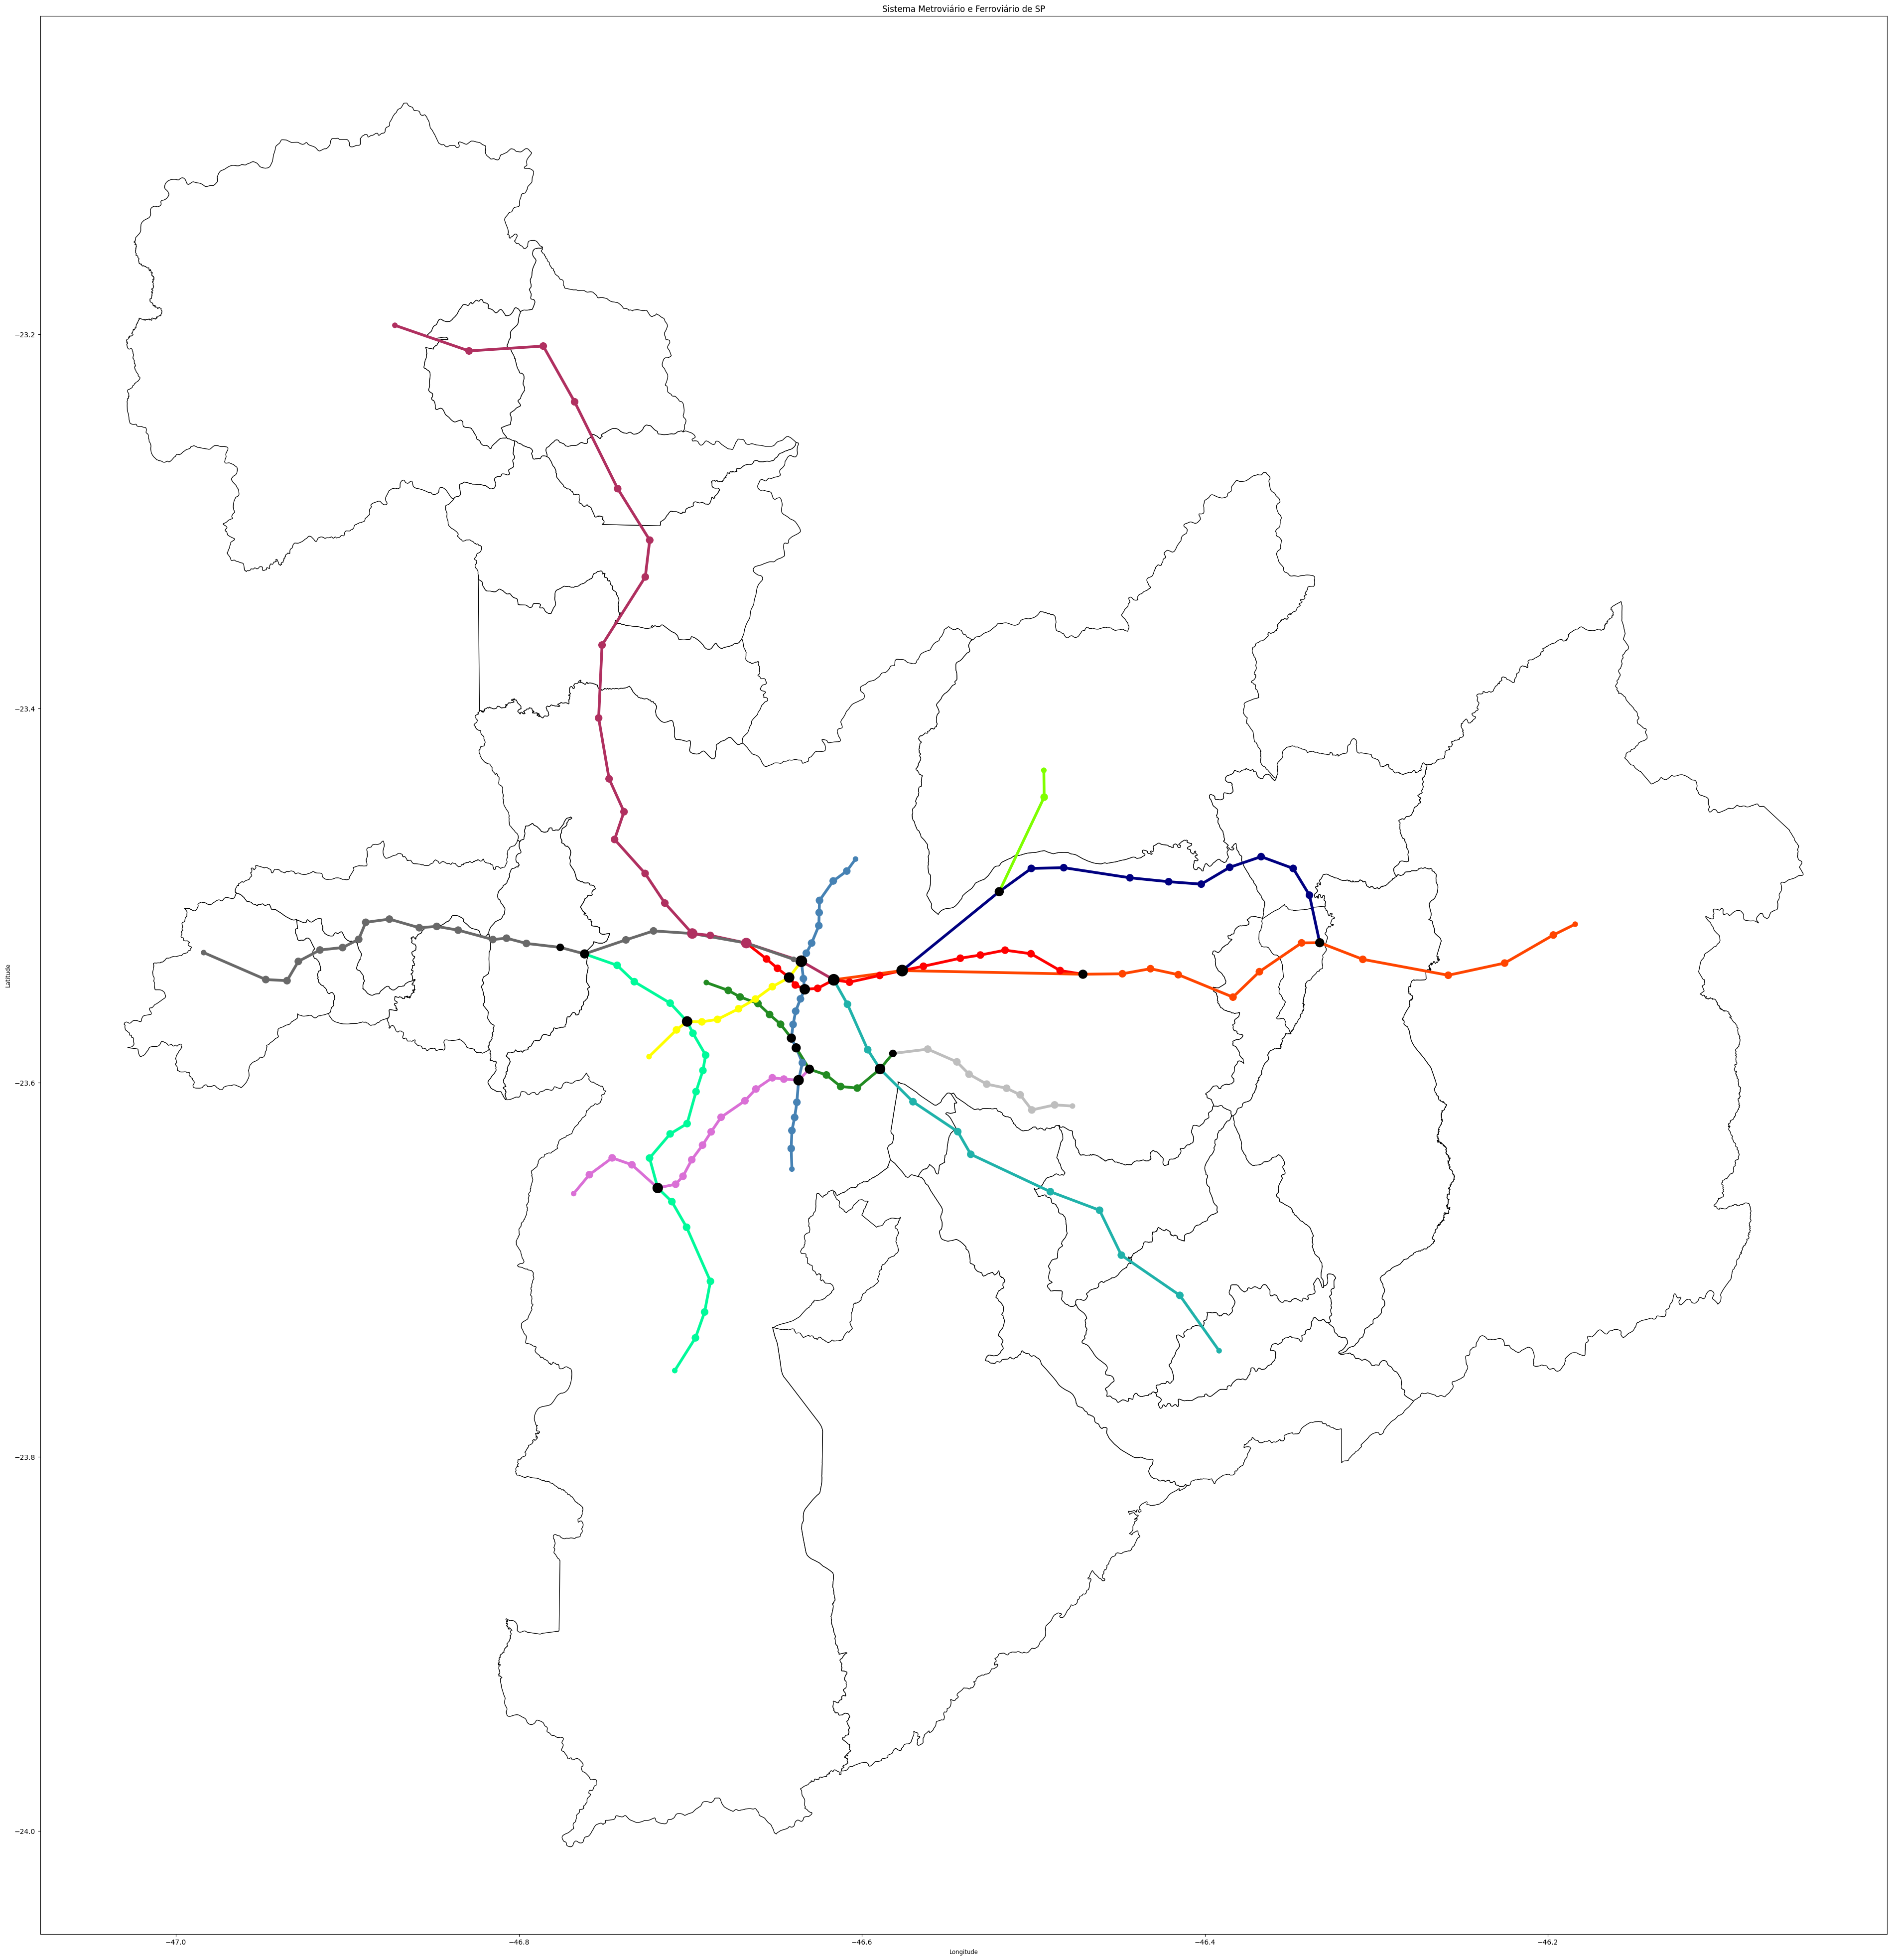

In [21]:
ax = MUNICIPIOS.plot(figsize=(50, 50), facecolor="white", edgecolor="black")
print("Sistema Metroviário e Ferroviário de SP - Sem Legenda")
t_nodes = [50 * G.degree(i) for i in G]
nx.draw(G, pos,  ax=ax, node_size=t_nodes, node_color=color, edge_color=cor_ar);
nx.draw_networkx_edges(G,pos, width=4.0,edge_color=cor_ar);
ax.set_axis_on()
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.title("Sistema Metroviário e Ferroviário de SP")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Sistema Metroviário e Ferroviário de SP - Com Legenda


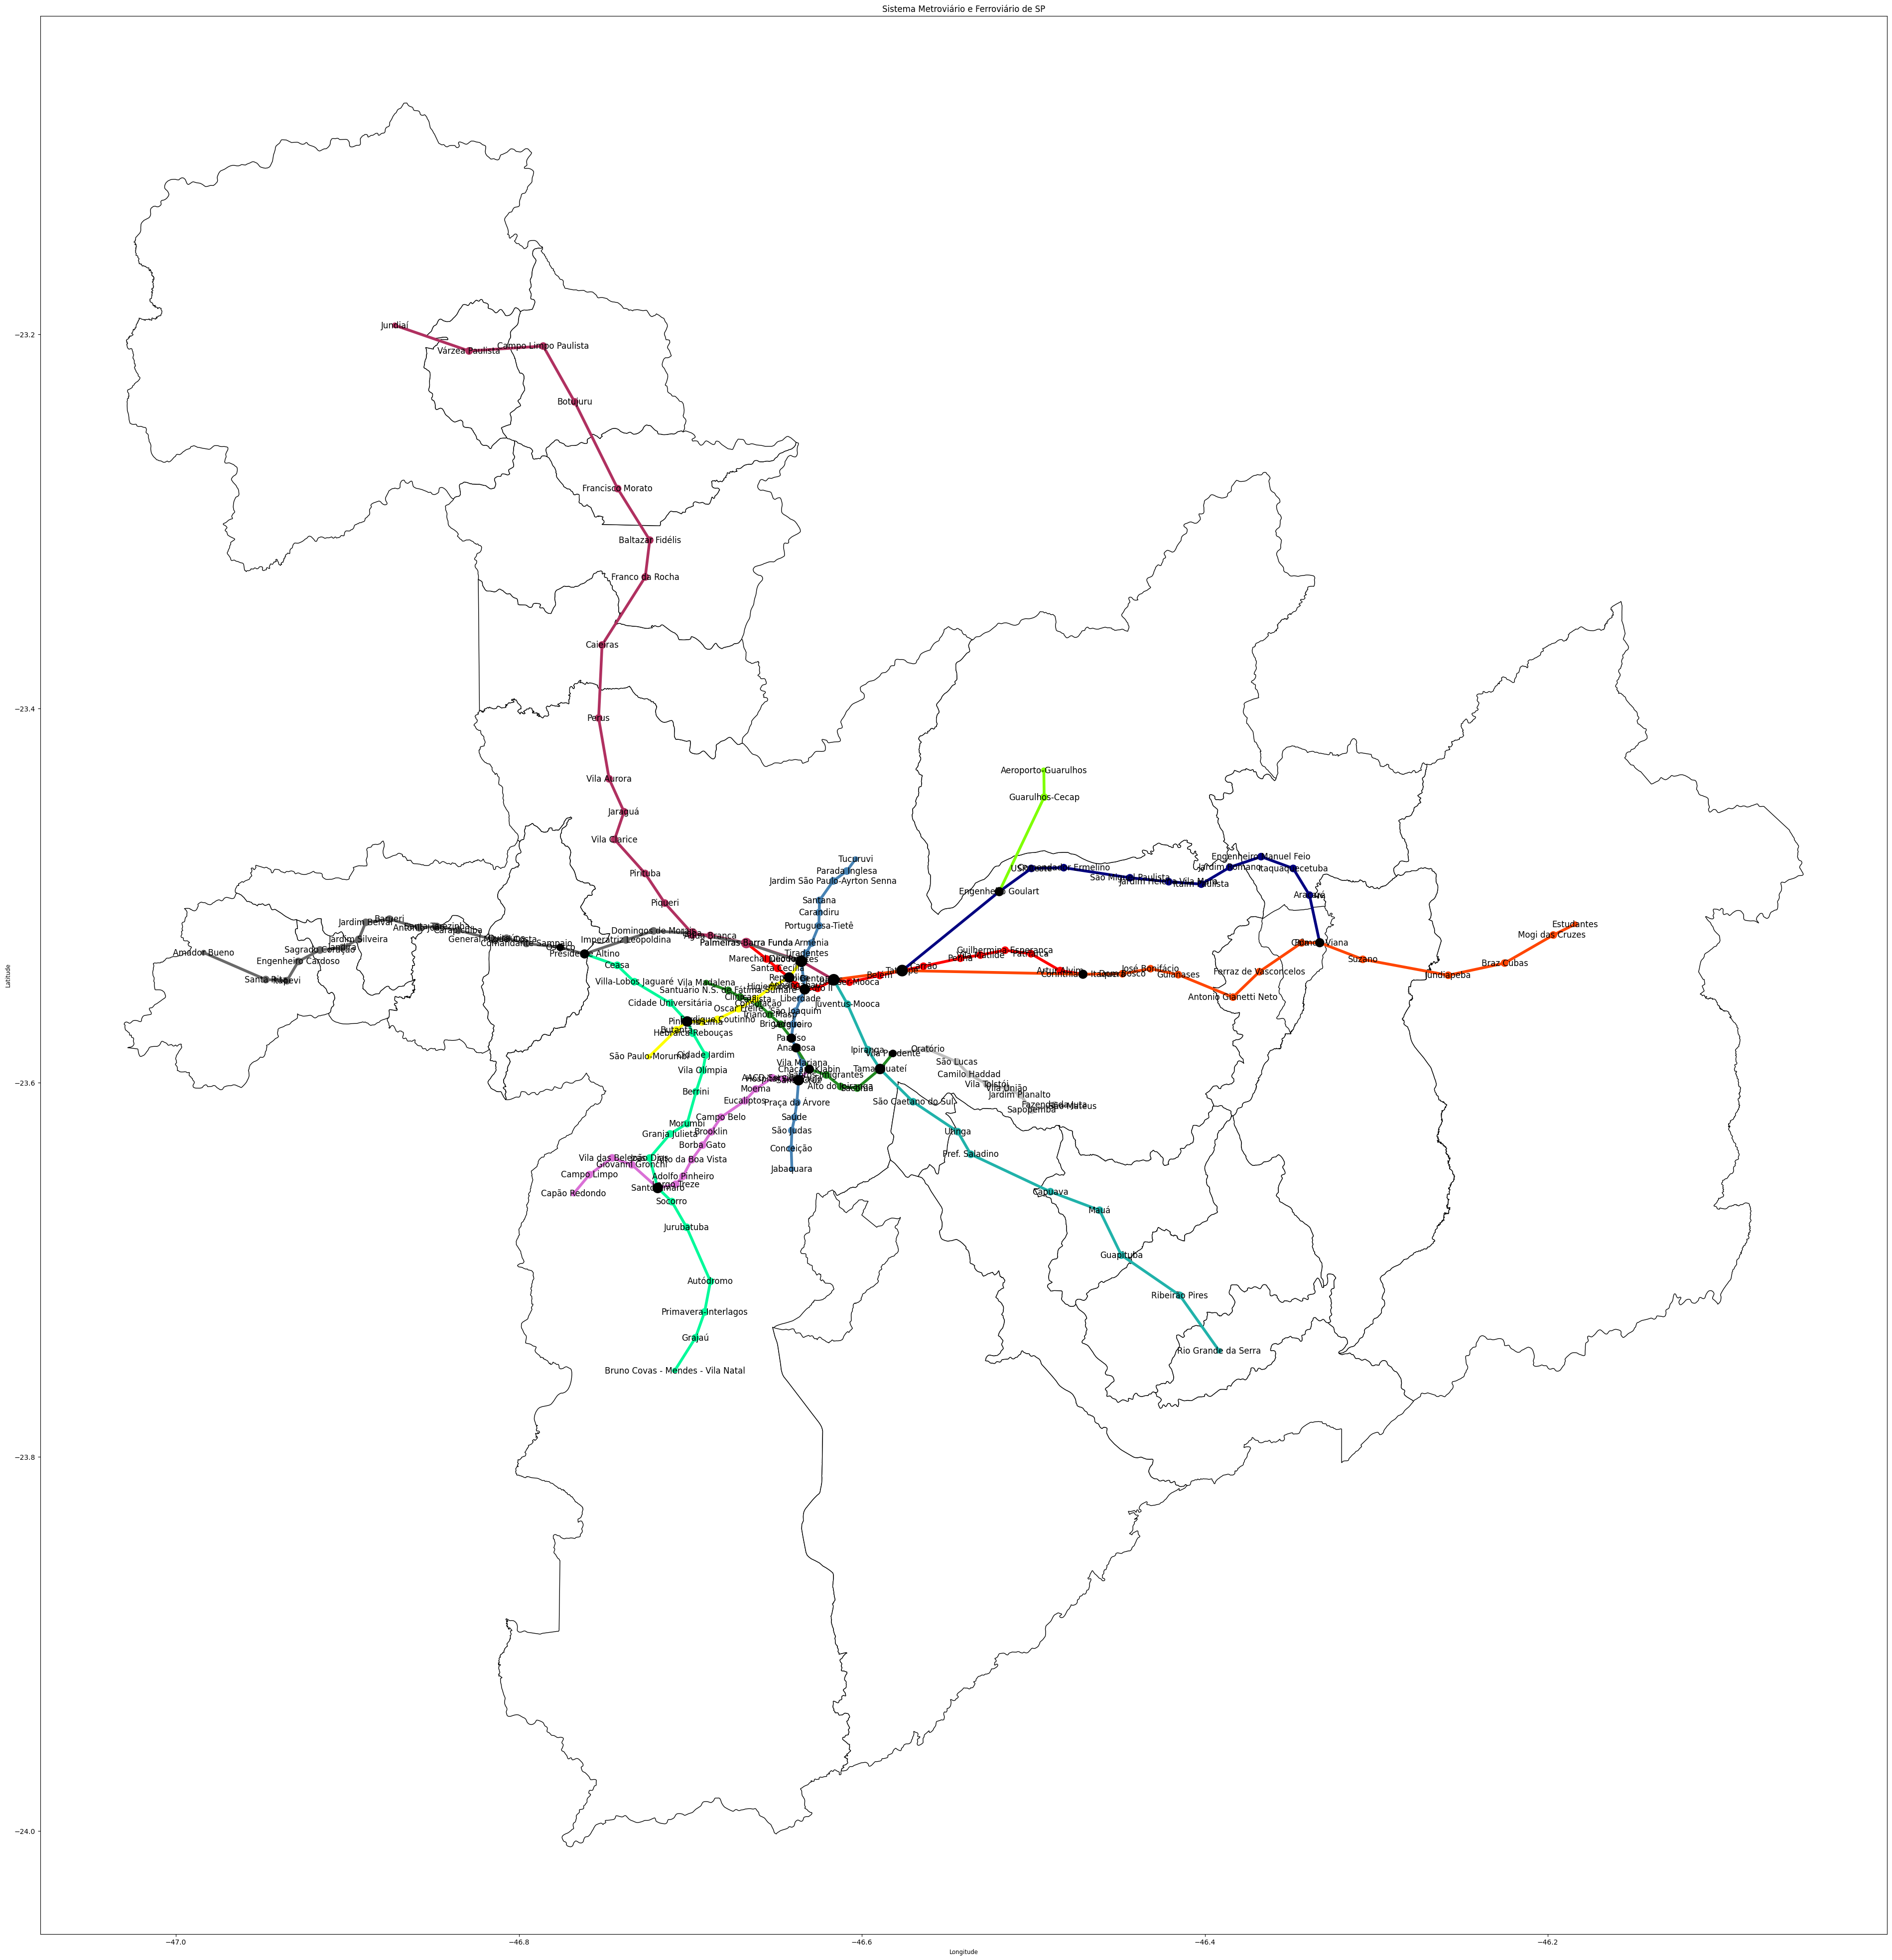

In [22]:
ax = MUNICIPIOS.plot(figsize=(50, 50), facecolor="white", edgecolor="black")
print("Sistema Metroviário e Ferroviário de SP - Com Legenda")
t_nodes = [50 * G.degree(i) for i in G]
nx.draw(G, pos, with_labels=True,  ax=ax, node_size=t_nodes, node_color=color, edge_color=cor_ar);
nx.draw_networkx_edges(G,pos, width=4.0,edge_color=cor_ar);
ax.set_axis_on()
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.title("Sistema Metroviário e Ferroviário de SP")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**LEGENDA:** As cores dos vértices e arestas estão de acordo com as cores das linhas do metrô e do trem. Os vértices em preto são as estações em que há conexão de linhas. O tamanho dos vértices é proporcional a quantidade de conexões (grau). Cada estação está na sua específica posição geográfica, de modo que o tamanho das arestas é proporcional a distância entre as estações. O plano de fundo é um representação dos municípios de SP que são conectados através das linhas de trem.

### **Subgrafo Somente das Linhas do Metrô**



In [23]:
FLUXO3 = pd.read_csv("/content/Entrada_de_Passageiros_por_Estação_Outubro_2021.csv", sep=",", skiprows=[0]) # ler banco de dados fornecido pelo Portal da Transparência Metrô

In [24]:
FLUXO3

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,DEMANDA DE PASSAGEIROS POR ESTAÇÃO* - MÉDIA D...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Linha 1 - Azul,NaN,Linha 2 - Verde,NaN,Linha 3 - Vermelha,NaN,Linha 15 - Prata,NaN
3,Estação,Entradas,Estação,Entradas,Estação,Entradas,Estação,Entradas
4,Jabaquara,57,Vila Prudente,54,Corinthians-Itaquera,62,Vila Prudente,42
5,Conceição,19,Tamanduateí,53,Artur Alvim,45,Oratório,4
6,São Judas,11,Sacomã,30,Patriarca,16,São Lucas,4
7,Saúde,20,Alto do Ipiranga,13,Guilhermina-Esperança,16,Camilo Haddad,3
8,Praça da Árvore,12,Santos-Imigrantes,10,Vila Matilde,20,Vila Tolstói,4
9,Santa Cruz,76,Chácara Klabin,54,Penha,22,Vila União,4


In [25]:
# renomeando as colunas restantes.
FLUXO2 = FLUXO3.rename(columns={"Unnamed: 0": "Linha 1", "Unnamed: 1": "Fluxo de Usuários (Linha 1)",
                      "Unnamed: 2": "Linha 2", "Unnamed: 3": "Fluxo de Usuários (Linha 2)",
                      "Unnamed: 4": "Linha 3", "Unnamed: 5": "Fluxo de Usuários (Linha 3)",
                      "Unnamed: 6": "Linha 15", "Unnamed: 7": "Fluxo de Usuários (Linha 15)",
                     })

# apagando as quatro primeiras linhas e a última.
delection = []

for i in range(0, 4):
  delection.append(i)
  if i == 3:
    delection.append(27)

FLUXO = FLUXO2.drop(delection)
FLUXO.reset_index(inplace = True, drop = True)  # redefine o índice.

In [26]:
FLUXO

,Linha 1,Fluxo de Usuários (Linha 1),Linha 2,Fluxo de Usuários (Linha 2),Linha 3,Fluxo de Usuários (Linha 3),Linha 15,Fluxo de Usuários (Linha 15)
0,Jabaquara,57,Vila Prudente,54,Corinthians-Itaquera,62,Vila Prudente,42
1,Conceição,19,Tamanduateí,53,Artur Alvim,45,Oratório,4
2,São Judas,11,Sacomã,30,Patriarca,16,São Lucas,4
3,Saúde,20,Alto do Ipiranga,13,Guilhermina-Esperança,16,Camilo Haddad,3
4,Praça da Árvore,12,Santos-Imigrantes,10,Vila Matilde,20,Vila Tolstói,4
5,Santa Cruz,76,Chácara Klabin,54,Penha,22,Vila União,4
6,Vila Mariana,13,Ana Rosa,46,Carrão,33,Jardim Planalto,3
7,Ana Rosa,53,Paraíso,47,Tatuapé,61,Sapopemba,6
8,Paraíso,65,Brigadeiro,32,Belém,29,Fazenda da Juta,3
9,Vergueiro,19,Trianon-Masp,28,Bresser-Moóca,24,São Mateus,15


In [27]:
# adiciona os vértices.

H = nx.Graph()

c = 1

while c <= 3:
  for i in METRO["Linha"+" "+str(c)]:
    if i != "- ":
      for j in range(0, 23):
        if i == METRO["Linha"+" "+str(c)][j]:
          H.add_node(i, pos=(float(METRO["Longitude"+" "+str(c)][j]), float(METRO["Latitude"+" "+str(c)][j])))

  c += 1

for i in METRO['Linha 15']:
  if i != "- ":
    for j in range(0, 23):
      if i == METRO["Linha 15"][j]:
        H.add_node(i, pos=(float(METRO["Longitude 15"][j]), float(METRO["Latitude 15"][j])))

In [28]:
# adiciona os arestas.

c = 1

while c <= 3:
  for i in range(0, 22):
    if METRO["Linha"+" "+str(c)][i+1] != "- ":
      H.add_edge(METRO["Linha"+" "+str(c)][i], METRO["Linha"+" "+str(c)][i+1])
  c += 1

for i in range(0, 22):
  if METRO["Linha 15"][i+1] != "- ":
    H.add_edge(METRO["Linha 15"][i], METRO["Linha 15"][i+1])

In [29]:
pos = nx.get_node_attributes(H,'pos')

In [30]:
# tamanho dos vértices.

size = []

for i in METRO["Linha 1"]:
  if i != "- ":
    for j in range(0, 23):
      if i.replace(" ", "") == FLUXO['Linha 1'][j].replace(" ", ""):
        if i == "Ana Rosa":
          size.append((int(99)*5))
        elif i == "Sé":
          size.append((int(297)*5))
        elif i == "Paraíso":
          size.append((int(112)*5))
        else:
          size.append((int(FLUXO["Fluxo de Usuários (Linha 1)"][j])*5))

for i in METRO["Linha 2"]:
  if i != "- ":
    for j in range(0, 23):
      if i.replace(" ", "") == FLUXO["Linha 2"][j].replace(" ", ""):
        if i == "Vila Prudente":
          size.append((int(96)*5))
        elif i != "Ana Rosa" and i != "Sé" and i != "Paraíso":
          size.append((float(FLUXO["Fluxo de Usuários (Linha 2)"][j])*5))

for i in METRO["Linha 3"]:
  if i != "- ":
    for j in range(0, 23):
      if i.replace(" ", "") == FLUXO["Linha 3"][j].replace(" ", ""):
        if i != "Ana Rosa" and i != "Sé" and i != "Paraíso" and i != "Vila Prudente":
          size.append((float(FLUXO["Fluxo de Usuários (Linha 3)"][j])*5))

for i in METRO["Linha 15"]:
  if i != "- ":
    for j in range(0, 23):
      if i.replace(" ", "") == FLUXO["Linha 15"][j].replace(" ", ""):
        if i != "Ana Rosa" and i != "Sé" and i != "Paraíso" and i != "Vila Prudente":
         size.append((float(FLUXO["Fluxo de Usuários (Linha 15)"][j])*5))

In [31]:
# cor das estações.

cor = []
estacoes = list(H.nodes)

for i in range(0, 61):
  if 0 <= i <= 22:
    if estacoes[i] != "Ana Rosa" and estacoes[i] != "Paraíso" and estacoes[i] != "Sé":
      cor.append("#4682B4")
    else:
      cor.append("gray")
  elif 22 < i <= 34:
    cor.append("#228B22")
  elif 34 < i <= 51:
    cor.append("red")
  else:
    cor.append("#BEBEBE")

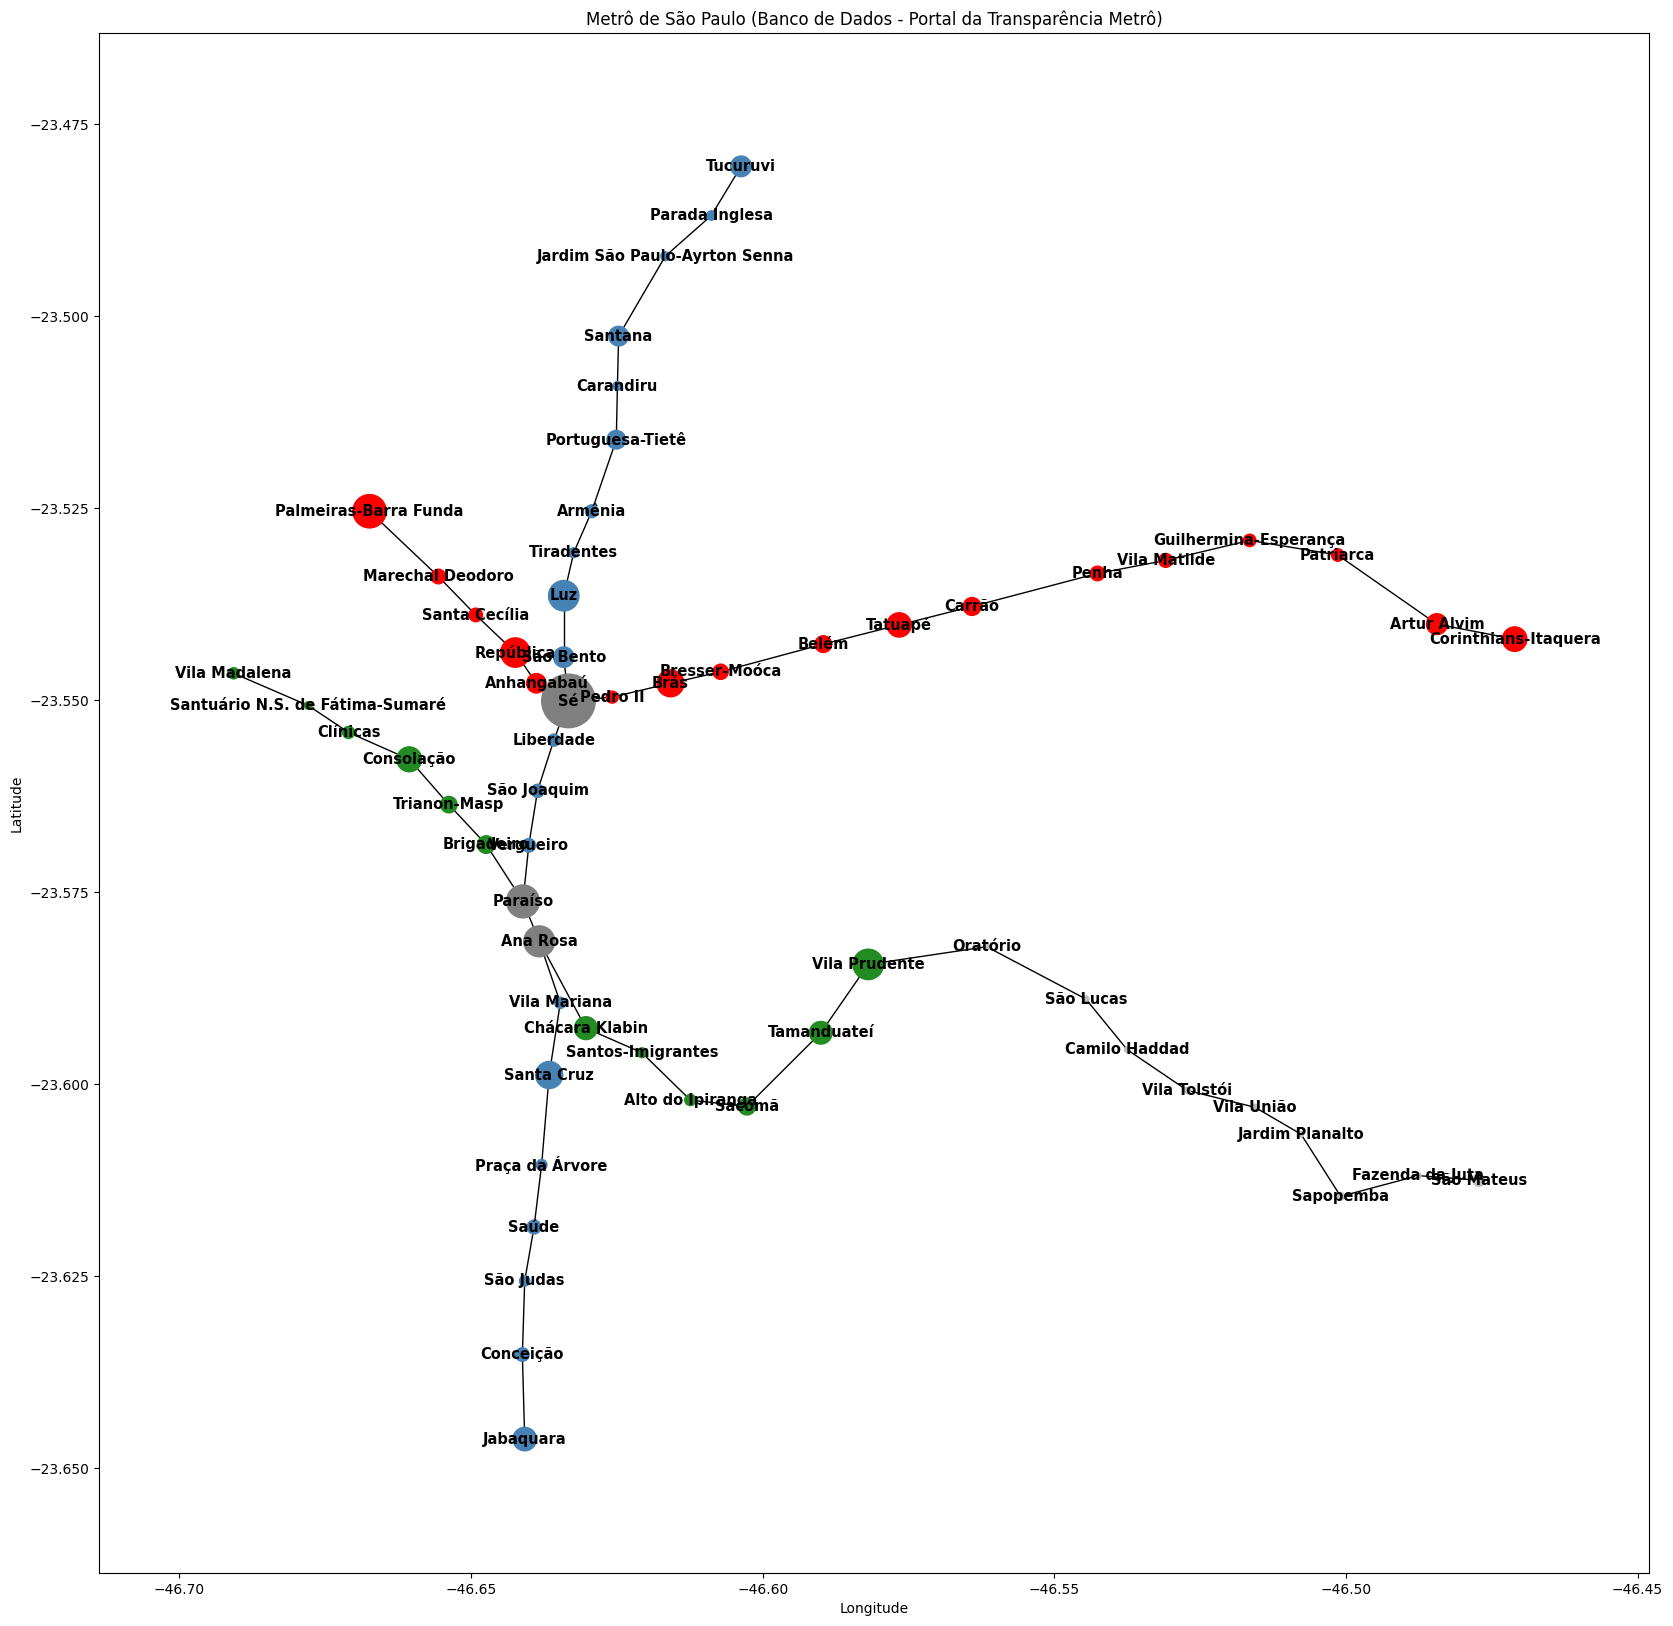

In [32]:
fig, ax = plt.subplots(figsize=(20, 20))
nx.draw(H, pos, with_labels=True, ax=ax, font_weight='bold', font_size=10.5, node_size=size, node_color=cor);
ax.set_axis_on()
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.title("Metrô de São Paulo (Banco de Dados - Portal da Transparência Metrô)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


**LEGENDA:** O tamanho das estações está de acordo com o fluxo de passageiros que passam por ela, os valores foram multiplicados por 5 para facilitar a visualização do grafo. A cor dos vértices está de acordo com a cor da linha a qual elas pertecem, entretanto, as estações que fazem integração com outras linhas estão com a cor cinza.  

### **Informações Gerais**

In [ ]:
print("INFORMAÇÕES DO GRAFO\n")
print('Número de vértices: ', G.number_of_nodes())
print('Número de arestas: ', G.number_of_edges())
graus = [val for (node, val) in G.degree()]
print('Grau médio: ', "{:.2f}".format( round(sum(graus) / G.number_of_nodes(), 2)) )
print('Grau máximo: ', max(graus))
print('Densidade: ', "{:.2f}".format( nx.density(G)) )
print('Coeficiente de Clusterização médio: ', "{:.2f}".format( nx.average_clustering(G)) )
print('Transitividade: ', "{:.2f}".format( round(nx.transitivity(G), 2)) )
print('Distância média: ', "{:.2f}".format( nx.average_shortest_path_length(G) ) if nx.is_connected(G) else "infinito")
print('Diâmetro: ', nx.diameter(G) if nx.is_connected(G) else "impossível calcular")
print('Componentes conexos: ', nx.number_connected_components(G))
print('Coreness do grafo: ',max(nx.core_number(G).values()))

INFORMAÇÕES DO GRAFO

Número de vértices:  171
Número de arestas:  180
Grau médio:  2.11
Grau máximo:  5
Densidade:  0.01
Coeficiente de Clusterização médio:  0.01
Transitividade:  0.01
Distância média:  14.27
Diâmetro:  36
Componentes conexos:  1
Coreness do grafo:  2


### **Centralidades**

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  from ipykernel import kernelapp as app


Sistema Metroviário e Ferroviário de SP - Centralidade de Grau


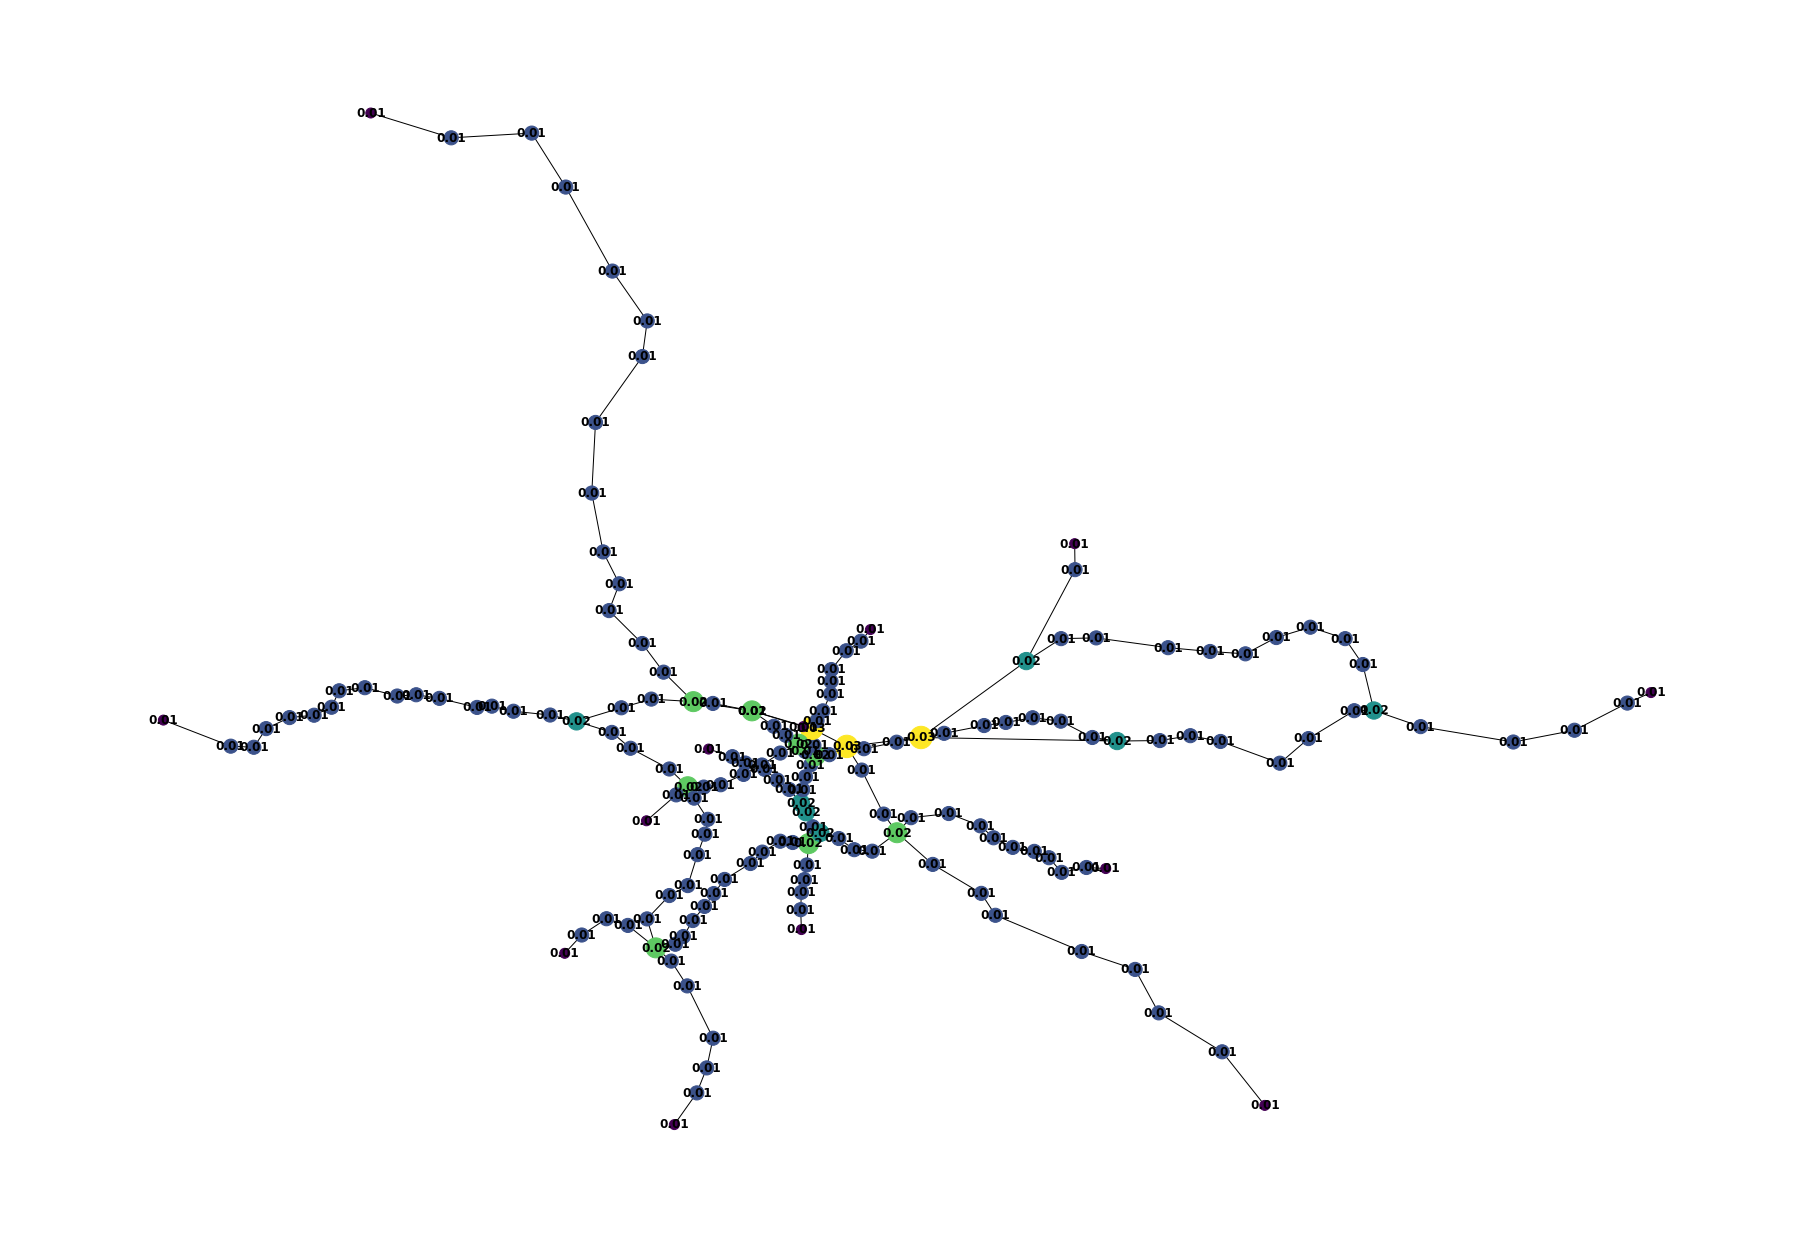

In [ ]:
# Grafo por Centralidade de Grau

cor_v = [nx.degree_centrality(G)[i] for i in G]
tamanho_v = [100 * G.degree(i) for i in G]

rotulo_v = {}
for v in G.nodes():
  rotulo_v[v] = round(nx.degree_centrality(G)[v], 2)

pos = nx.get_node_attributes(G,'pos');
plt.figure(figsize =(25, 17));
nx.draw(G,pos, node_size = tamanho_v, node_color = cor_v);
nx.draw_networkx_labels(G,pos, rotulo_v, font_color = 'black',font_weight='bold');
plt.axis('off')
plt.tight_layout();
print("Sistema Metroviário e Ferroviário de SP - Centralidade de Grau")

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  from ipykernel import kernelapp as app


Sistema Metroviário e Ferroviário de SP - Centralidade Relativa de Proximidade


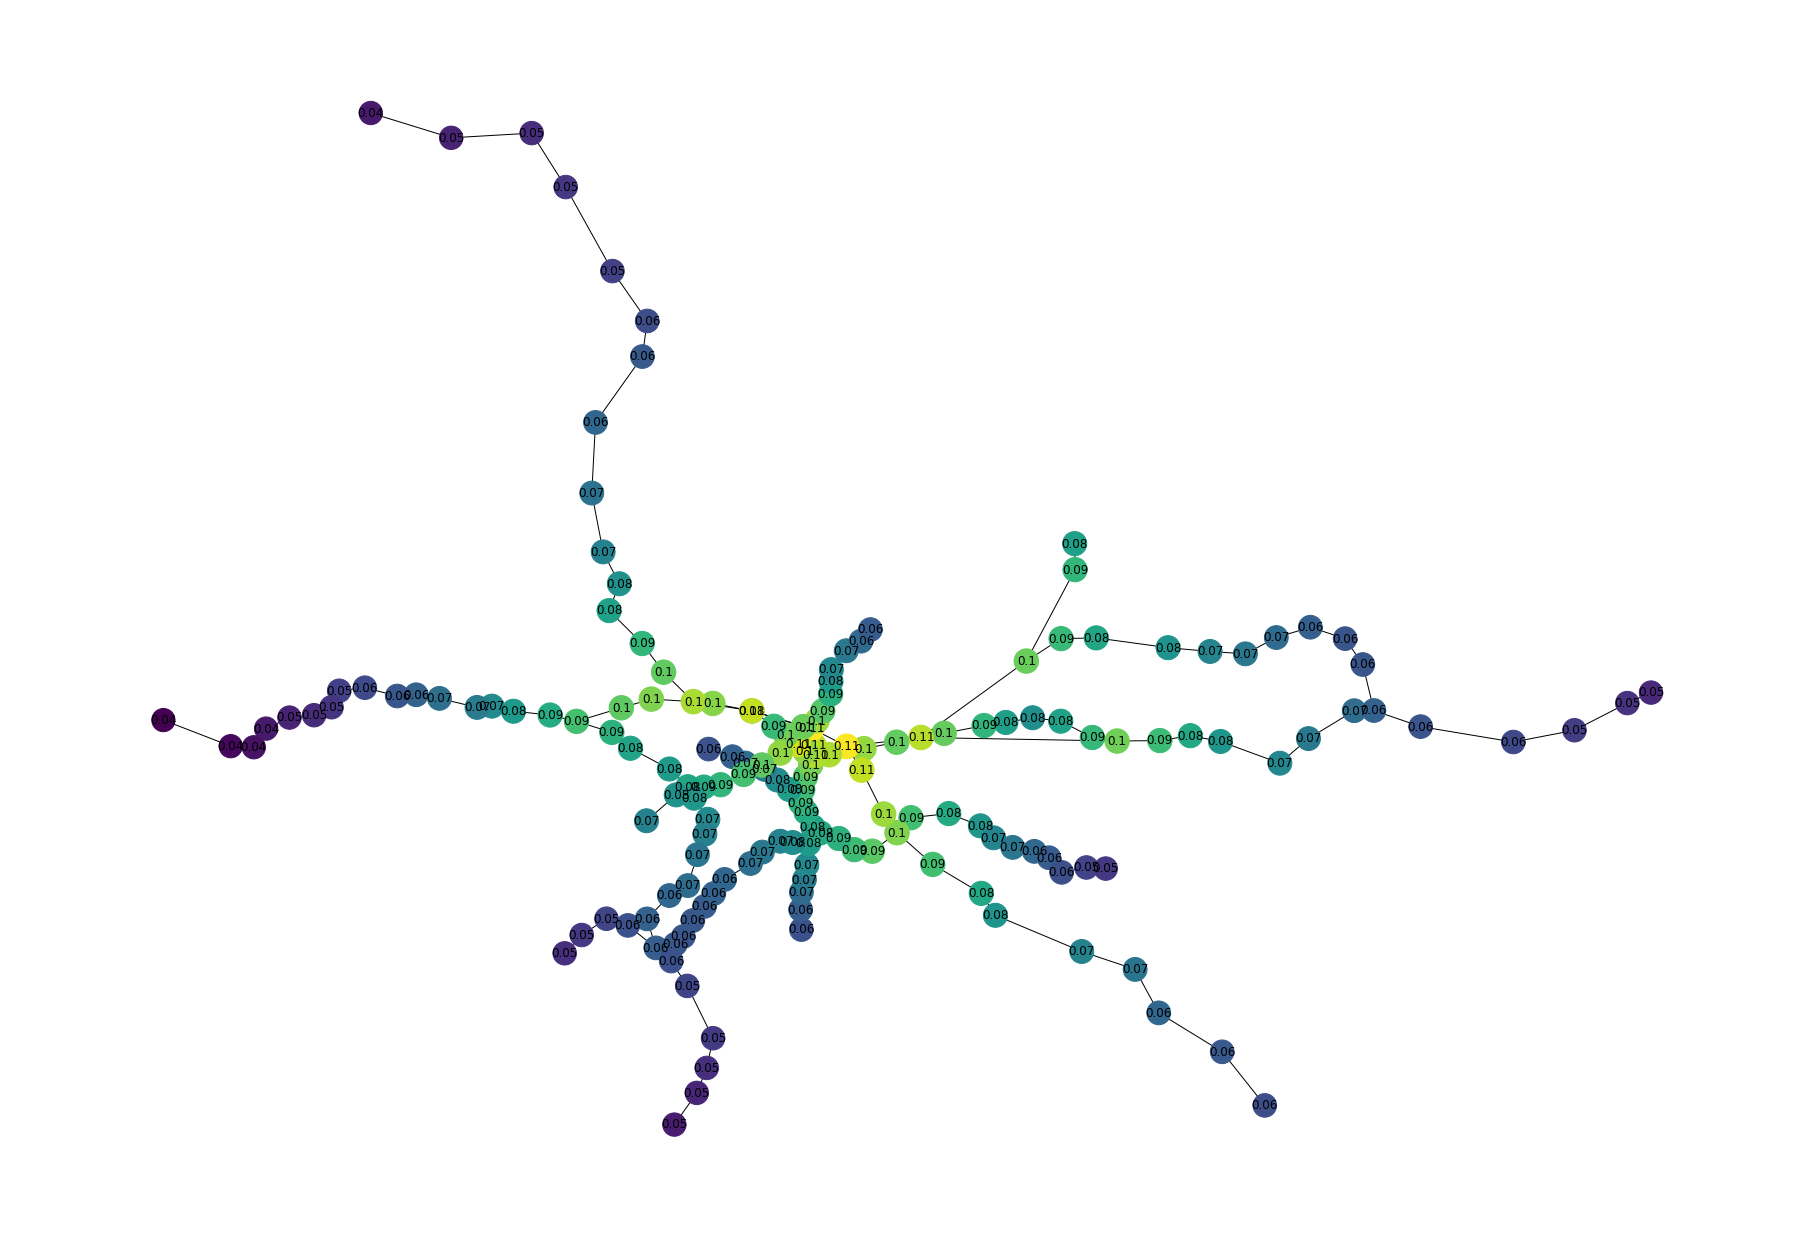

In [ ]:
# Grafo por Centralidade Relativa de Proximidade

cor_v = [nx.closeness_centrality(G)[i] for i in G]
tamanho_v = [500 + 1000 * nx.closeness_centrality(G)[i] for i in G]

rotulo_v = {}
for v in G.nodes():
  rotulo_v[v] = round(nx.closeness_centrality(G)[v], 2)

pos = nx.get_node_attributes(G,'pos');
plt.figure(figsize =(25, 17));
nx.draw(G,pos, node_size = tamanho_v, node_color = cor_v);
nx.draw_networkx_labels(G,pos, rotulo_v, font_color = 'black' );
plt.axis('off')
plt.tight_layout();
print("Sistema Metroviário e Ferroviário de SP - Centralidade Relativa de Proximidade")

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  from ipykernel import kernelapp as app


Sistema Metroviário e Ferroviário de SP - Centralidade Relativa de Intermediação


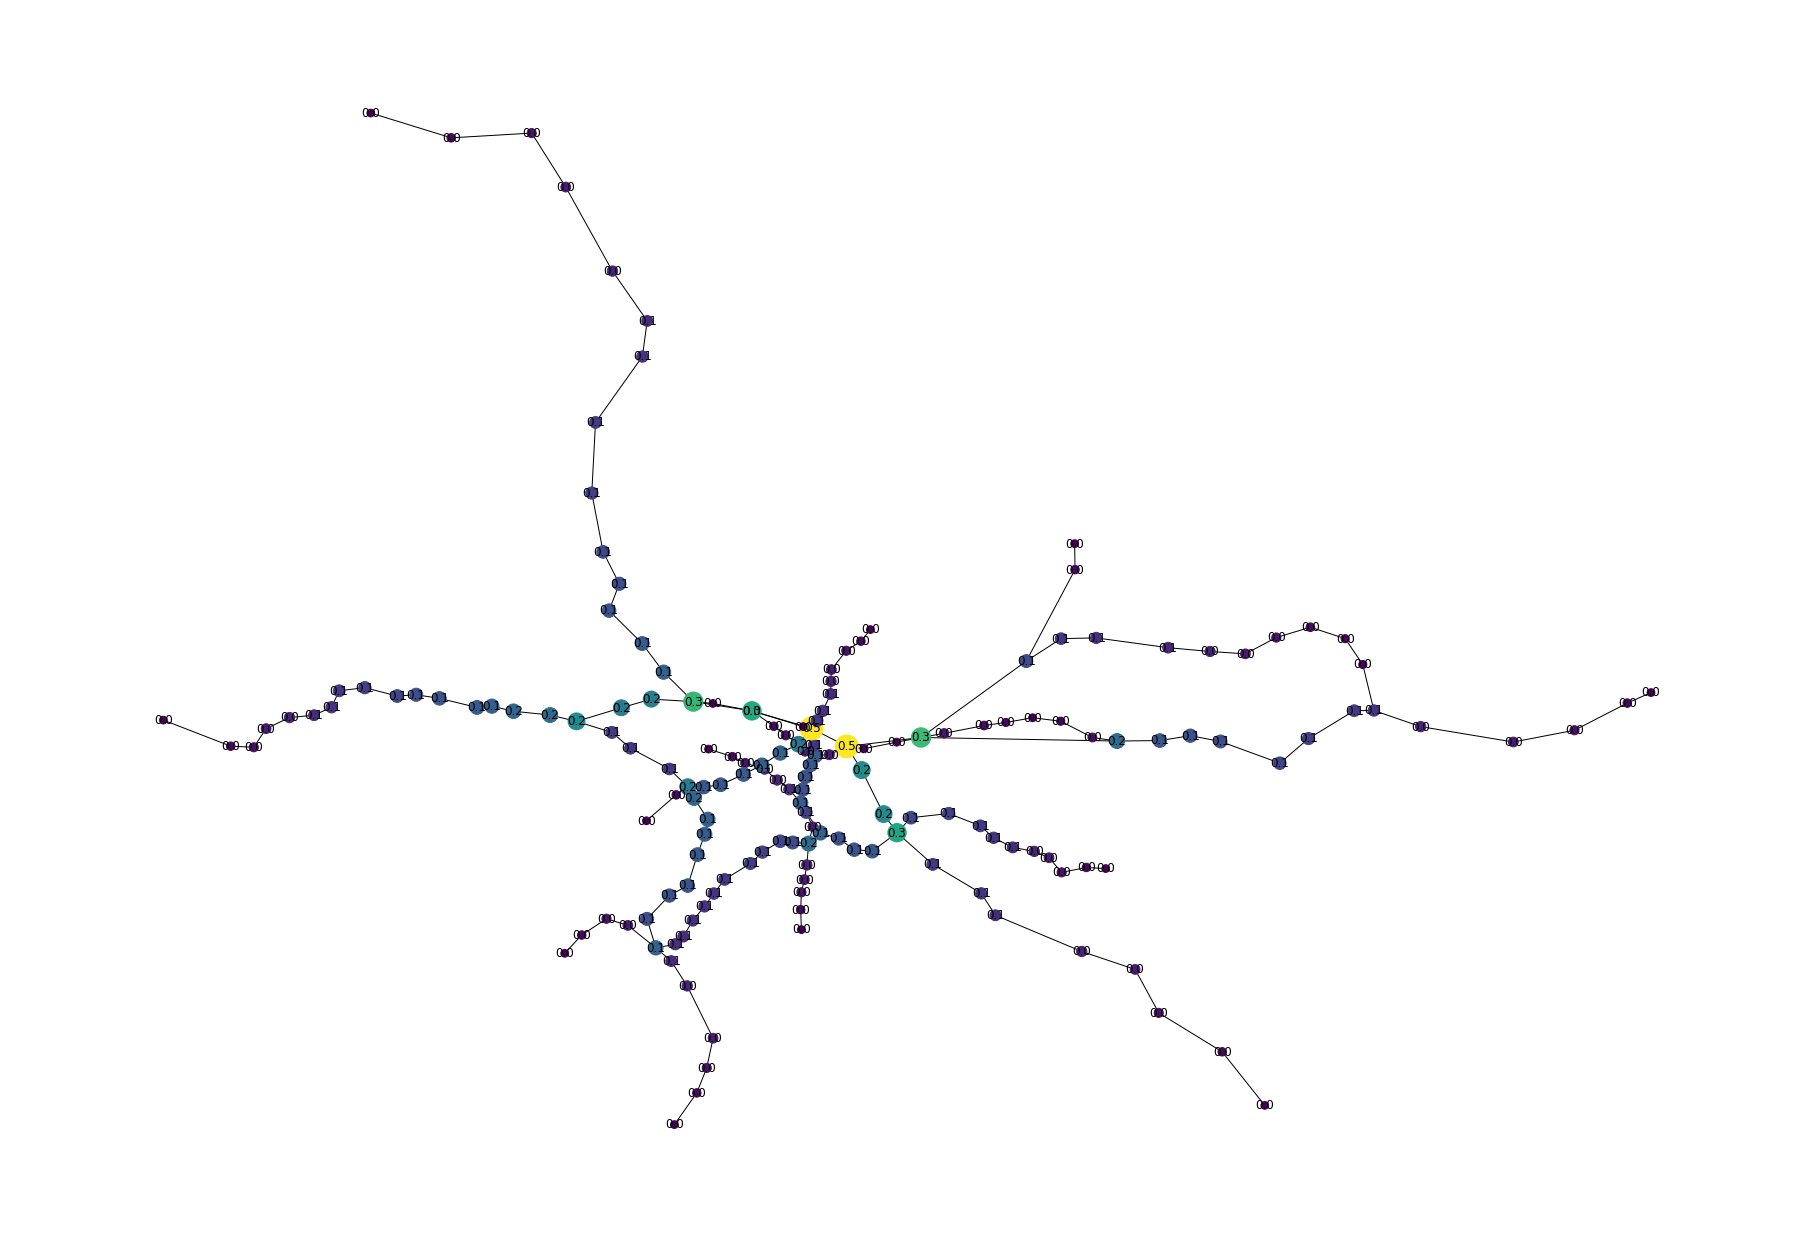

In [ ]:
# Grafo por Centralidade Relativa de Intermediação

cor_v = [nx.betweenness_centrality(G)[i] for i in G]
tamanho_v = [60 + 1000 * nx.betweenness_centrality(G)[i] for i in G]

rotulo_v = {}
for v in G.nodes():
  rotulo_v[v] = round(nx.betweenness_centrality(G)[v], 1)

pos = nx.get_node_attributes(G,'pos');
plt.figure(figsize =(25, 17));
nx.draw(G,pos, node_size = tamanho_v, node_color = cor_v);
nx.draw_networkx_labels(G,pos, rotulo_v, font_color = 'black' );
plt.axis('off')
plt.tight_layout();
print("Sistema Metroviário e Ferroviário de SP - Centralidade Relativa de Intermediação")

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  from ipykernel import kernelapp as app


Sistema Metroviário e Ferroviário de SP - Coreness


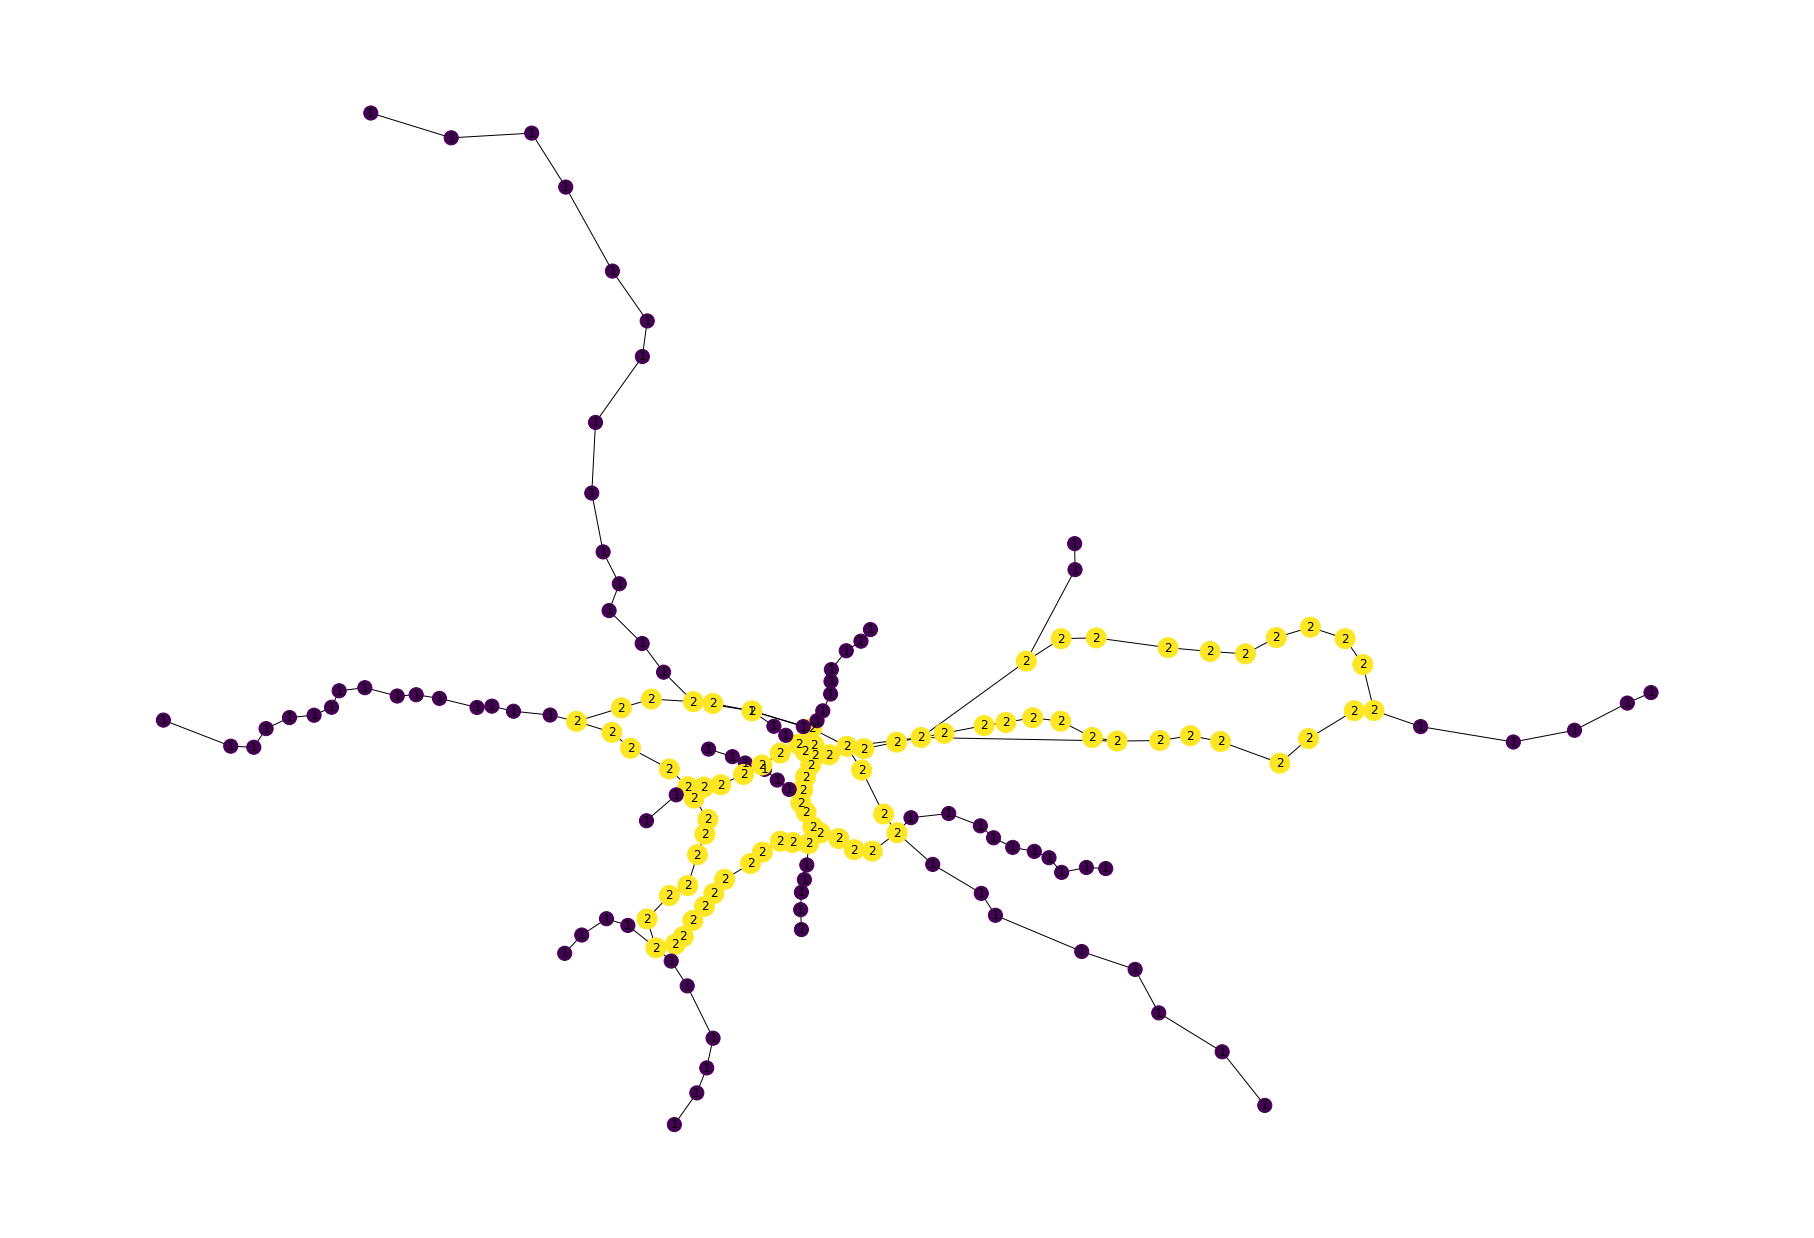

In [ ]:
# Grafo de acordo com o Coreness

cor_v = [nx.core_number(G)[i] for i in G]
tamanho_v = [200 * nx.core_number(G)[i] for i in G]

rotulo_v = {}
for v in G.nodes():
  rotulo_v[v] = nx.core_number(G)[v]

pos = nx.get_node_attributes(G,'pos');
plt.figure(figsize =(25, 17));
nx.draw(G,pos, node_size = tamanho_v, node_color = cor_v);
nx.draw_networkx_labels(G,pos, rotulo_v, font_color = 'black' );
plt.axis('off')
plt.tight_layout();
print("Sistema Metroviário e Ferroviário de SP - Coreness")

In [ ]:
def draw(G, pos, measures, measure_name):

    nodes = nx.draw_networkx_nodes(G, pos, node_size=8, cmap=plt.cm.plasma,
                                   node_color=list(measures.values()),
                                   nodelist=measures.keys())
    edges = nx.draw_networkx_edges(G, pos)

    plt.title(measure_name)
    plt.colorbar(nodes)
    plt.axis('off')
    plt.show()

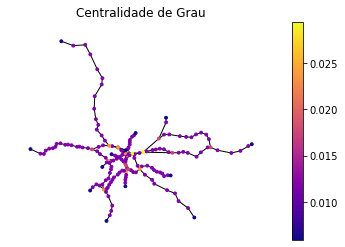

In [ ]:
draw(G, pos, nx.degree_centrality(G), 'Centralidade de Grau')

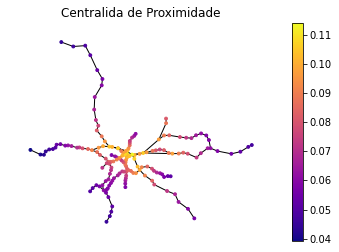

In [ ]:
draw(G, pos, nx.closeness_centrality(G), 'Centralida de Proximidade')

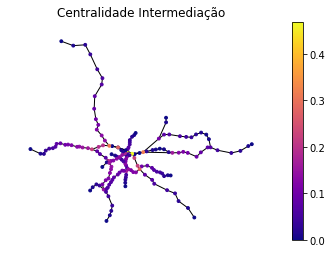

In [ ]:
draw(G, pos, nx.betweenness_centrality(G), 'Centralidade Intermediação')

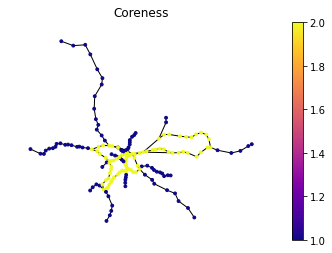

In [ ]:
draw(G, pos, nx.core_number(G), 'Coreness')

### **Histogramas e Distribuições**

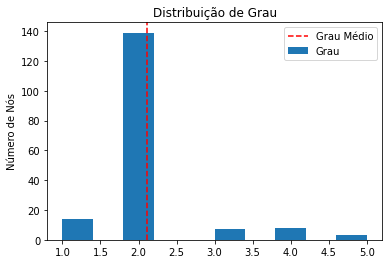

In [ ]:
lista_grau = []
for (n,d) in G.degree():
  lista_grau.append(d)

av_grau = sum(lista_grau) / len(lista_grau)

plt.hist(lista_grau,label='Grau')
plt.axvline(av_grau,color='r',linestyle='dashed',label='Grau Médio')
plt.legend()
plt.ylabel('Número de Nós')
plt.title('Distribuição de Grau')
plt.show()

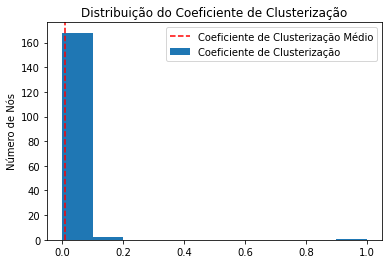

In [ ]:
coe_clus = nx.algorithms.cluster.clustering(G)

av_coe_clus = sum(coe_clus.values())/len(coe_clus)

plt.hist(coe_clus.values(),label='Coeficiente de Clusterização')
plt.axvline(av_coe_clus,color='r',linestyle='dashed',label='Coeficiente de Clusterização Médio')
plt.legend()
plt.ylabel('Número de Nós')
plt.title('Distribuição do Coeficiente de Clusterização')
plt.show()

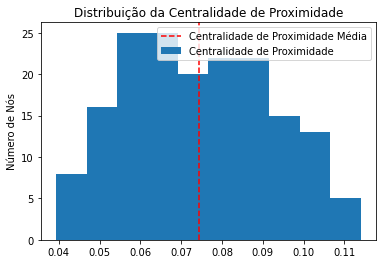

In [ ]:
cen_prox = nx.closeness_centrality(G)

av_cen_prox = sum(cen_prox.values())/len(cen_prox)

plt.hist(cen_prox.values(),label='Centralidade de Proximidade')
plt.axvline(av_cen_prox,color='r',linestyle='dashed',label='Centralidade de Proximidade Média')
plt.legend()
plt.ylabel('Número de Nós')
plt.title('Distribuição da Centralidade de Proximidade')
plt.show()

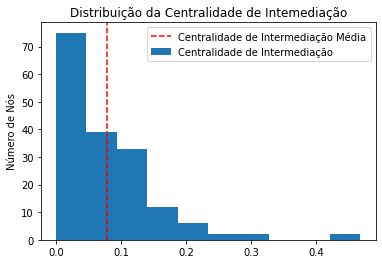

In [ ]:
cen_inter = nx.betweenness_centrality(G)

av_cen_inter = sum(cen_inter.values())/len(cen_inter)

plt.hist(cen_inter.values(),label='Centralidade de Intermediação')
plt.axvline(av_cen_inter,color='r',linestyle='dashed',label='Centralidade de Intermediação Média')
plt.legend()
plt.ylabel('Número de Nós')
plt.title('Distribuição da Centralidade de Intemediação')
plt.show()

### **Comunidades**

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


Número de Comunidades Formadas:  12
Comunidades Formadas:  [frozenset({'Carrão', 'Estudantes', 'Guianases', 'Antonio Gianetti Neto', 'Braz Cubas', 'Mogi das Cruzes ', 'Ferraz de Vasconcelos', 'Guilhermina-Esperança', 'Suzano', 'Penha', 'Calmon Viana', 'Patriarca', 'Bresser-Moóca', 'José Bonifácio', 'Brás', 'Dom Bosco', 'Tatuapé', 'Póa', 'Artur Alvim', 'Belém', 'Corinthians-Itaquera', 'Vila Matilde', 'Jundiapeba'}), frozenset({'Tucuruvi', 'Carandiru', 'Tiradentes', 'Santana', 'Portuguesa-Tietê', 'República', 'Paraíso', 'Jardim São Paulo-Ayrton Senna', 'Palmeiras-Barra Funda', 'Pedro II', 'Parada Inglesa', 'Liberdade', 'São Joaquim', 'São Bento', 'Anhangabaú', 'Vergueiro', 'Luz', 'Marechal Deodoro', 'Sé', 'Santa Cecília', 'Armênia'}), frozenset({'Santo Amaro', 'Socorro', 'Largo Treze', 'Eucaliptos', 'Brooklin', 'Moema', 'Jurubatuba', 'Giovanni Gronchi', 'Campo Belo', 'Primavera-Interlagos', 'Bruno Covas - Mendes - Vila Natal', 'Autódromo', 'Capão Redondo', 'Alto da Boa Vista', 'Campo Lim

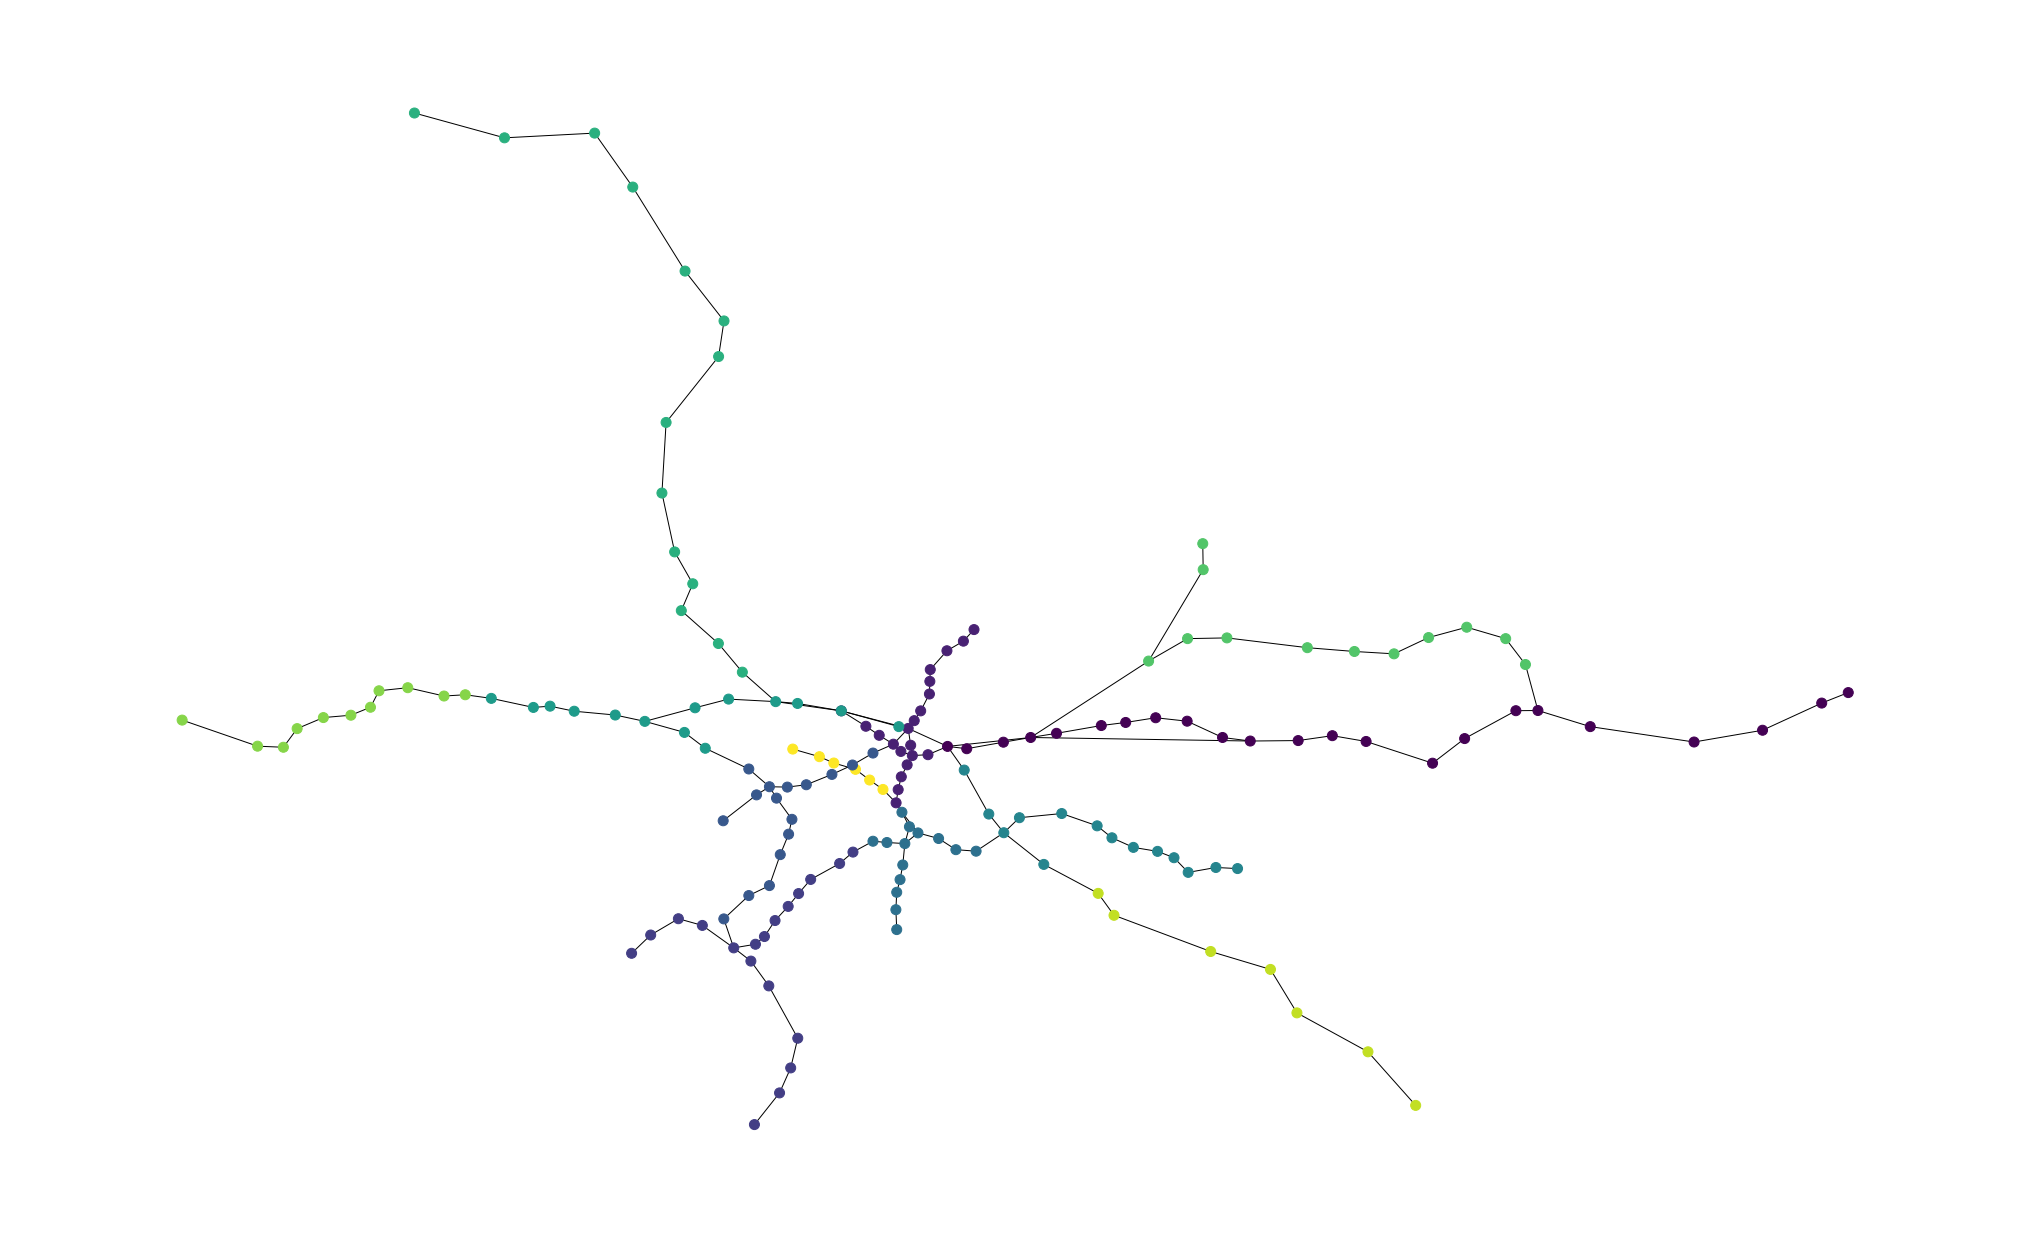

In [ ]:
from networkx.algorithms.community.modularity_max import greedy_modularity_communities

com = greedy_modularity_communities(G)

no_cor = {}
for i, lg in enumerate(com):
    for node in lg:
        no_cor[node] = i
node_cor = [no_cor[n] for n in G.nodes]

plt.figure(figsize =(28, 17));
nx.draw(G, pos, node_color=node_cor, node_size=100);
plt.axis('off');
plt.tight_layout();

print("Número de Comunidades Formadas: ", len(com))
print("Comunidades Formadas: ", list(com))

# **Menor Distância Entre Estações**



In [ ]:
# Menor Distância entre vértices (Executável)

estacao1 = input("Digite o nome da estação de origem: ")
estacao2 = input("Digite o nome da estação destino: ")

d = (nx.shortest_path_length(G, source = estacao1, target = estacao2))+1
print("\nQuantidade de Estações a Serem Percorridas:", d)

mc = nx.shortest_path(G, estacao1, method='dijkstra', weight='weight')

print("Estações a Serem Percorridas:", mc[estacao2])

Digite o nome da estação de origem: Ribeirão Pires
Digite o nome da estação destino: Brás

Quantidade de Estações a Serem Percorridas: 11
Estações a Serem Percorridas: ['Ribeirão Pires', 'Guapituba', 'Mauá', 'Capuava', 'Pref. Saladino', 'Utinga', 'São Caetano do Sul', 'Tamanduateí', 'Ipiranga', 'Juventus-Mooca', 'Brás']


**Legenda:** Ao executar o código o usuário poderá traçar o menor caminho entre sua estação atual e a estação desejada.



# **Conclusão**

- Comunidades: O algoritmo utilizado detectou 12 comunidades diante das 13 linhas existentes de metrô e de trem. Apesar da semelhança dos números, visualmente percebe-se que as comunidades encotradas não são as linhas do metrô e do trêm. Portanto, por mais que seja uma comparação interessante, conclui-se que não é possível distinguir as linhas de metrô e trem deste grafo, utilizando-se desse algoritmo de detecção de comunidades.
- Tendo em vista, que o Metrô e o Trem veem sendo um dos meios preferidos de locomoção entre os paulistanos, e também que todos esses anos de modernização foram convenientes para o surgimento de diversas linhas, pode-se compreender com todas as representações usadas acima a grande abrangência em que essas linhas conseguem alcançar toda região metropolitana de São Paulo, sendo então os meios de transportes mais eficiêntes, capazes de cruzar as cidades em um périodo relativamente pequeno, ressaltando também que as estações que fazem baldeação, são muito eficazes para essas conexões, o que faz com que diversos trajetos sejam possivéis e convenientes, tornando a cidade de São Paulo e as regiões em seu entorno mais dinâmicas e abertas a possibilidades de crescimento econômico e social.

# **Contribuições dos membros da equipe**

Todos os membros do grupo contribuíram igualmente para a realização do projeto, realizando com sucesso cada uma das suas funções. Sendo assim, pode-se dizer que cada um dos três integrantes contribuiu 33.3% para a realização do projeto.

# **Refêrencias**

**Fluxo de Passageiros -** Banco de dados retirado do portal da Transparência do Metrô, com informações referentes ao fluxo de pessoas nas estações das linhas 1, 2, 3 e 15 no mês de outubro de 2021. LINK: https://transparencia.metrosp.com.br/dataset/demanda/resource/fc56cc34-de1c-447e-a67c-42bed67aad05

**Cor dos Vértices e Arestas -** http://mmatos-design.blogspot.com/2011/02/tabela-de-cores-em-rgb.html

**Municípios do Estado de São Paulo -** https://www.ibge.gov.br/geociencias/downloads-geociencias.html

**Resumo -** https://super.abril.com.br/mundo-estranho/qual-a-diferenca-entre-trem-e-metro/

http://www.ferreoclube.com.br/2015/12/03/ferrovia-e-revolucao-industria/#:~:text=A%20ferrovia%20%C3%A9%20de%20todos,e%20espa%C3%A7o%20conhecidas%20at%C3%A9%20ent%C3%A3o.

https://diariodotransporte.com.br/2019/07/14/historia-companhia-paulista-da-estrada-de-ferro-de-jundiahy-a-campinas/

https://noticiando.net/memorias-do-transporte-metro-de-sao-paulo-completa-52-anos/

https://www.cptm.sp.gov.br/a-companhia/Pages/Nossa-Historia.aspx

**Coordenadas das Linhas de Metrô e Trem-** Banco de dados feito manualmente através do Google Maps https://www.google.com.br/maps